# Libraries

In [1]:
import os
import mne
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import pandas as pd

from mpl_toolkits.axes_grid1 import make_axes_locatable
from mne.viz import plot_compare_evokeds
import scipy


# for save and load dict variables
import pickle

# General parameters

In [2]:
# working directory
work_dir = '/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/'

# subjects to exclude
exclude_ppts = [
    '0027', # vot, incomplete eeg recording due to wrong sound library setting
    '0028', # f0, missing block 3 and 4
    '0030', # missing block 3 and 4
    '0034', # missing block 3
    '0040', # f0, missing block 3 and 4
    '0046', # f0, missing block 2,3,4

    # '0008', # too many bad trials
    # '0024', # too many bad trials
    # '0037', # too many bad trials
    
    # '0005', # non-native
    # '0010', # non-native
    # '0015', # non-native
    # '0020', # non-native
    # '0023', # non-native
    # '0025', # non-native
    # '0026', # left-handed
    # '0045', # 
]

# create a dictionary for condition key and standard and deviant cells ####
cell_dict = {
    'VOT': {
        # 'wMMN_glottal_longVOT': {'stan': 'glottal_lowStan_highDevi_stan', 'devi': 'glottal_lowStan_highDevi_devi',   'stan_stim': 'short VOT', 'devi_stim': 'long VOT'},
        # 'wMMN_glottal_shortVOT': {'stan': 'glottal_highStan_lowDevi_stan', 'devi': 'glottal_highStan_lowDevi_devi',  'stan_stim': 'long VOT', 'devi_stim': 'short VOT'},
        # 'wMMN_dorsal_longVOT': {'stan': 'dorsal_lowStan_highDevi_stan', 'devi': 'dorsal_lowStan_highDevi_devi',      'stan_stim': 'short VOT', 'devi_stim': 'long VOT'},
        # 'wMMN_dorsal_shortVOT': {'stan': 'dorsal_highStan_lowDevi_stan', 'devi': 'dorsal_highStan_lowDevi_devi',     'stan_stim': 'long VOT', 'devi_stim': 'short VOT'},
        'iMMN_dorsal_longVOT': {'stan': 'dorsal_highStan_lowDevi_stan', 'devi': 'dorsal_lowStan_highDevi_devi',      'stan_stim': 'long VOT', 'devi_stim': 'long VOT'}, 
        'iMMN_dorsal_shortVOT': {'stan': 'dorsal_lowStan_highDevi_stan', 'devi': 'dorsal_highStan_lowDevi_devi',     'stan_stim': 'short VOT', 'devi_stim': 'short VOT'},
        'iMMN_glottal_longVOT': {'stan': 'glottal_highStan_lowDevi_stan', 'devi': 'glottal_lowStan_highDevi_devi',   'stan_stim': 'long VOT', 'devi_stim': 'long VOT'},
        'iMMN_glottal_shortVOT': {'stan': 'glottal_lowStan_highDevi_stan', 'devi': 'glottal_highStan_lowDevi_devi',  'stan_stim': 'short VOT', 'devi_stim': 'short VOT'},
    },

    'F0': {
        # 'wMMN_glottal_highF0': {'stan': 'glottal_lowStan_highDevi_stan', 'devi': 'glottal_lowStan_highDevi_devi',    'stan_stim': 'low F0', 'devi_stim': 'high F0'},
        # 'wMMN_glottal_lowF0': {'stan': 'glottal_highStan_lowDevi_stan', 'devi': 'glottal_highStan_lowDevi_devi',     'stan_stim': 'high F0', 'devi_stim': 'low F0'},
        # 'wMMN_dorsal_highF0': {'stan': 'dorsal_lowStan_highDevi_stan', 'devi': 'dorsal_lowStan_highDevi_devi',       'stan_stim': 'low F0', 'devi_stim': 'high F0'},
        # 'wMMN_dorsal_lowF0': {'stan': 'dorsal_highStan_lowDevi_stan', 'devi': 'dorsal_highStan_lowDevi_devi',        'stan_stim': 'high F0', 'devi_stim': 'low F0'},
        'iMMN_dorsal_highF0': {'stan': 'dorsal_highStan_lowDevi_stan', 'devi': 'dorsal_lowStan_highDevi_devi',       'stan_stim': 'high F0', 'devi_stim': 'high F0'},
        'iMMN_dorsal_lowF0': {'stan': 'dorsal_lowStan_highDevi_stan', 'devi': 'dorsal_highStan_lowDevi_devi',        'stan_stim': 'low F0', 'devi_stim': 'low F0'},
        'iMMN_glottal_highF0': {'stan': 'glottal_highStan_lowDevi_stan', 'devi': 'glottal_lowStan_highDevi_devi',    'stan_stim': 'high F0', 'devi_stim': 'high F0'},
        'iMMN_glottal_lowF0': {'stan': 'glottal_lowStan_highDevi_stan', 'devi': 'glottal_highStan_lowDevi_devi',     'stan_stim': 'low F0', 'devi_stim': 'low F0'},
    }
}

# Single-participant eeg

In [3]:
# times to show in topoplots (in seconds)
times = [0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]

##### function #####
def myfunc_single_ppt_plot(input_dir, ppt):

    # get group and file info
    file = ppt + '_ave.fif'
    group = ppt.split('_')[0]

    # plot
    for cell in cell_dict[group].keys():
        
        # get erp
        erp_stan = mne.read_evokeds(fname=input_dir+file, condition=cell_dict[group][cell]['stan'], verbose='WARNING')
        erp_devi = mne.read_evokeds(fname=input_dir+file, condition=cell_dict[group][cell]['devi'], verbose='WARNING')
        erp_diff = mne.combine_evoked([erp_devi, erp_stan], weights=[1,-1])
        
        # get legends
        legend_stan = 'standard (' + cell_dict[group][cell]['stan_stim'] + ')'
        legend_devi = 'deviant (' + cell_dict[group][cell]['devi_stim'] + ')'
        # legend_diff = 'deviants minus standards'
        
        
        ##########################
        ####  ERP Topographical subplot and ROI waveforms ####
        ##########################
        
        
        # combine data for plotting
        evokeds = {}
        evokeds[legend_stan] = erp_stan.filter(l_freq=None, h_freq=30, verbose='WARNING')
        evokeds[legend_devi] = erp_devi.filter(l_freq=None, h_freq=30, verbose='WARNING')
        # evokeds[legend_diff] = erp_diff.filter(l_freq=None, h_freq=30)
        
        
        
        ################################
        #### Topographical subplots ####
        ################################
        
        # figure title for the waveform
        title = ppt + '_' + cell
        
        ##############################
        # waveforms across scalp topo
        # NOTE: I don't know how to save these plots using the code
        fig = mne.viz.plot_compare_evokeds(
            evokeds,
            axes='topo',
            # picks=pick_chans,
            # combine="mean",
            show_sensors=True,
            # colors=colors,
            title = title,
            # ylim=dict(eeg=[-5, 5]),
            time_unit="ms",
            show=False,
        );
        # figure title for the waveform
        ##############################
        # waveforms across scalp topo
        # NOTE: I don't know how to save these plots using the code
    
        erp_diff.filter(l_freq=None, h_freq=30, verbose='WARNING').plot_topomap(times)
        ##### function end #####

## Toronto data

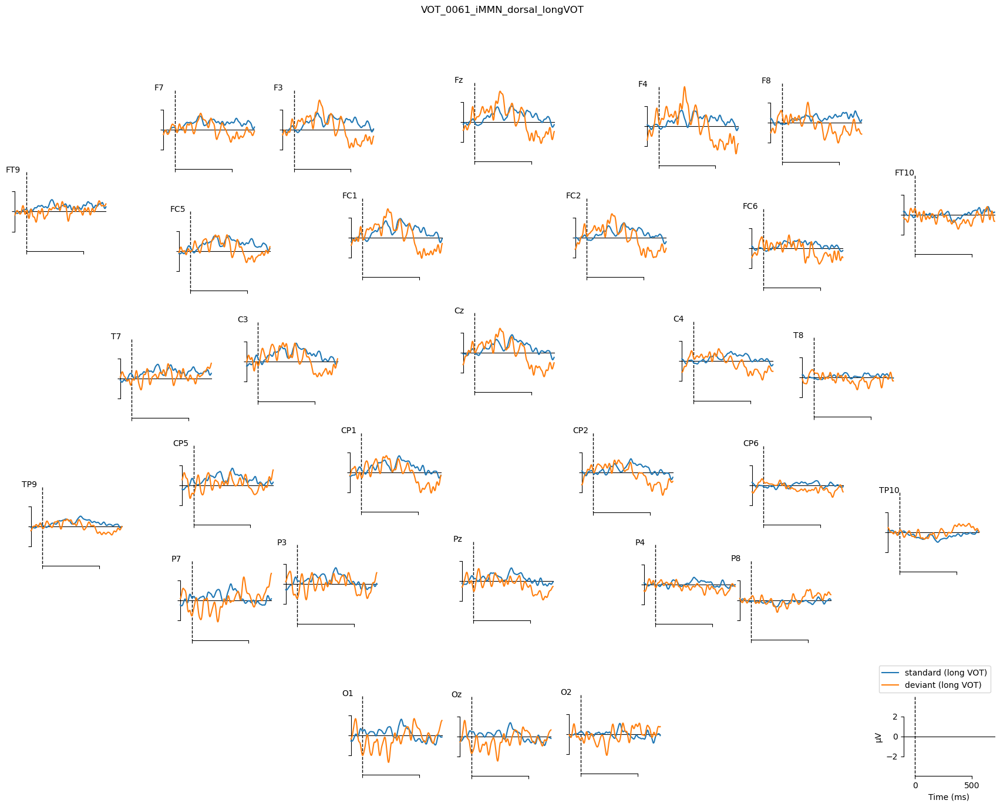

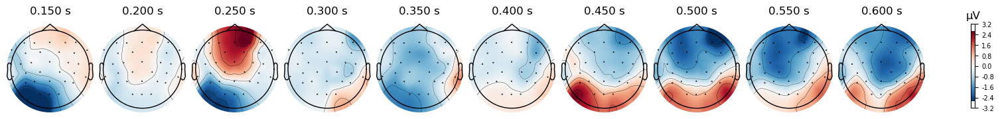

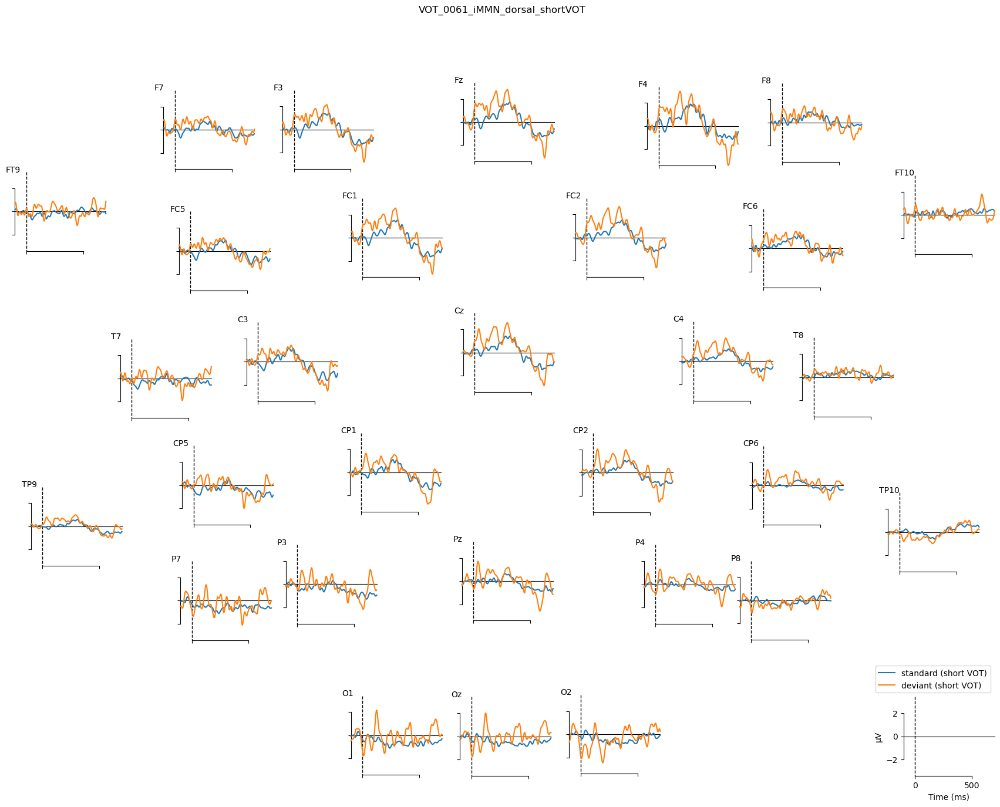

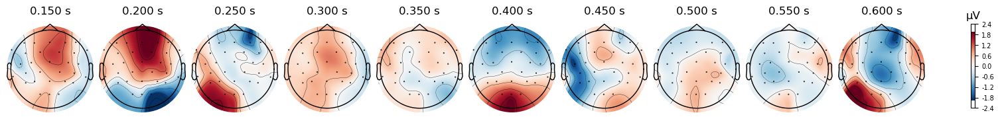

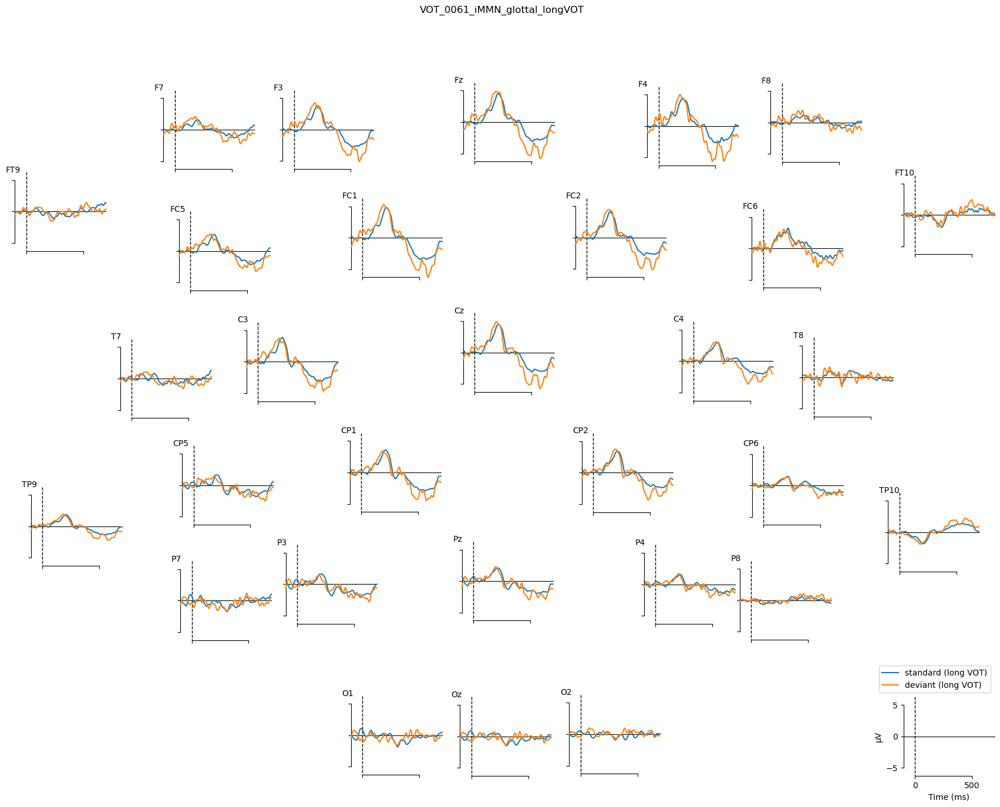

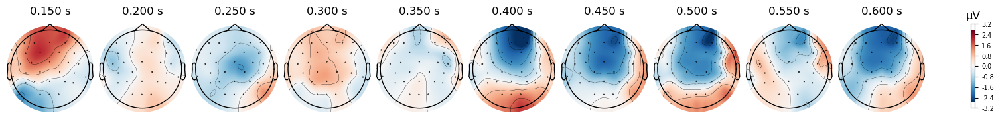

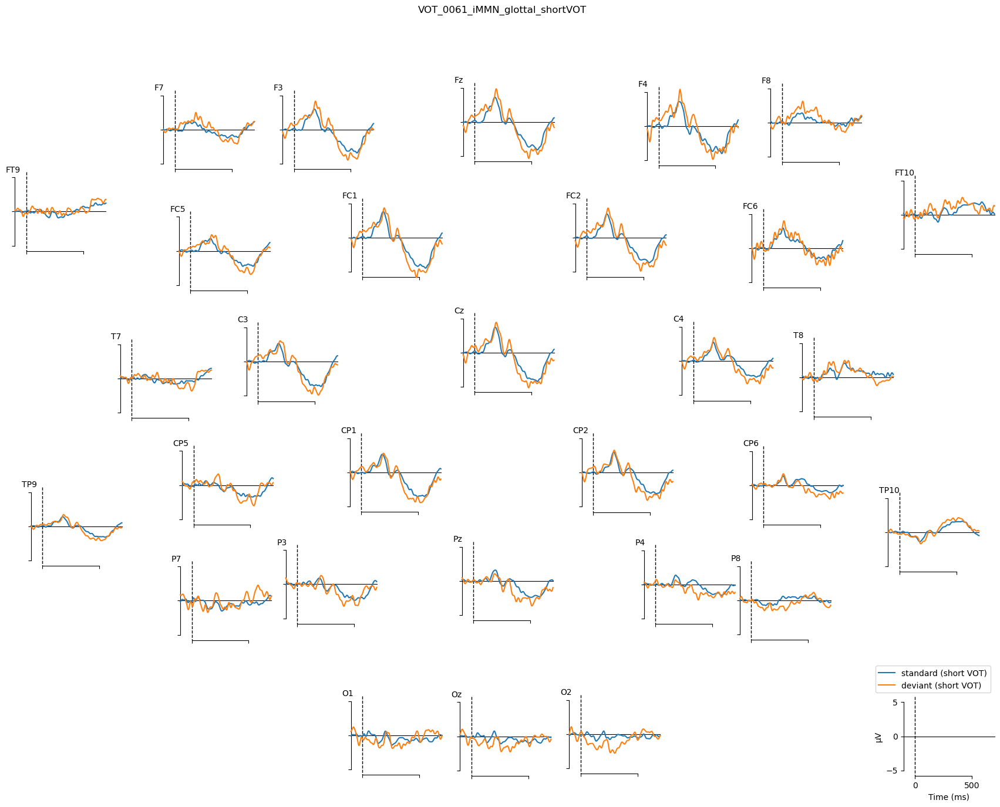

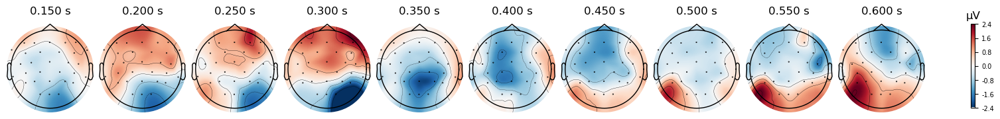

In [10]:
##### Toronto #####
# directory
input_dir = work_dir + 'data_preprocessed/5_evokeds/'
# participant
ppt = 'VOT_0061'
# plot
myfunc_single_ppt_plot(input_dir, ppt)

## Seoul data

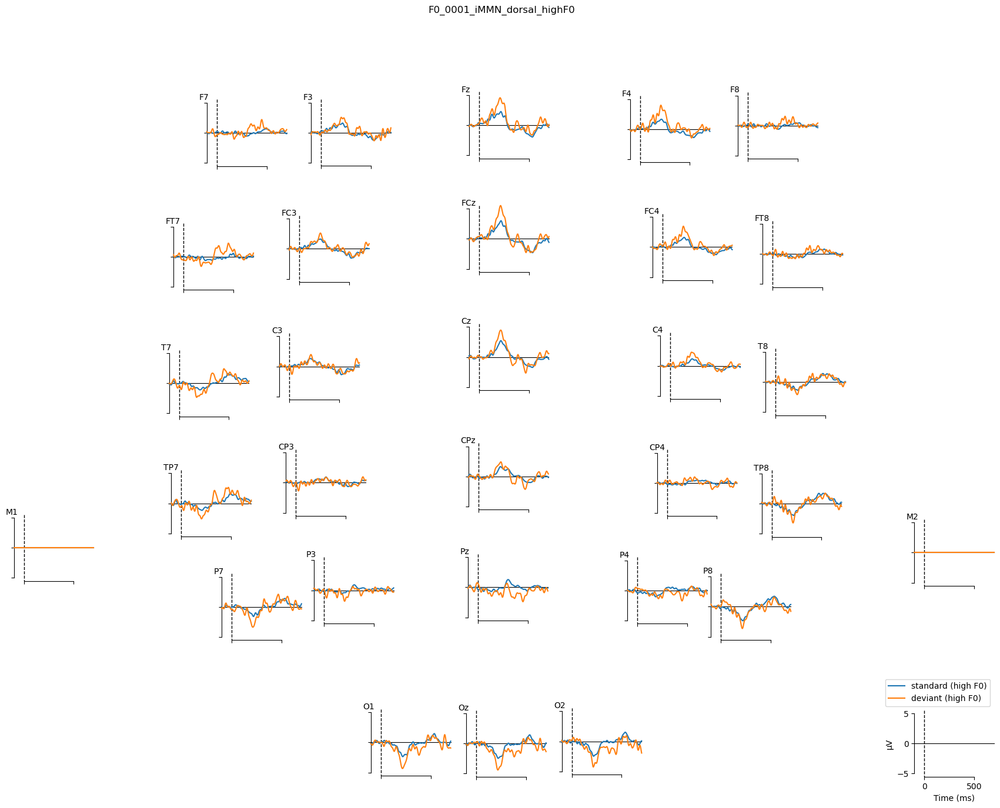

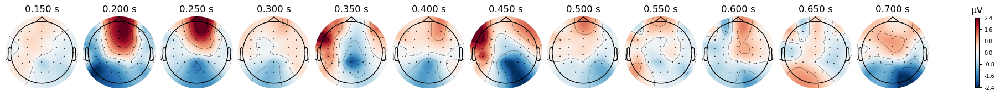

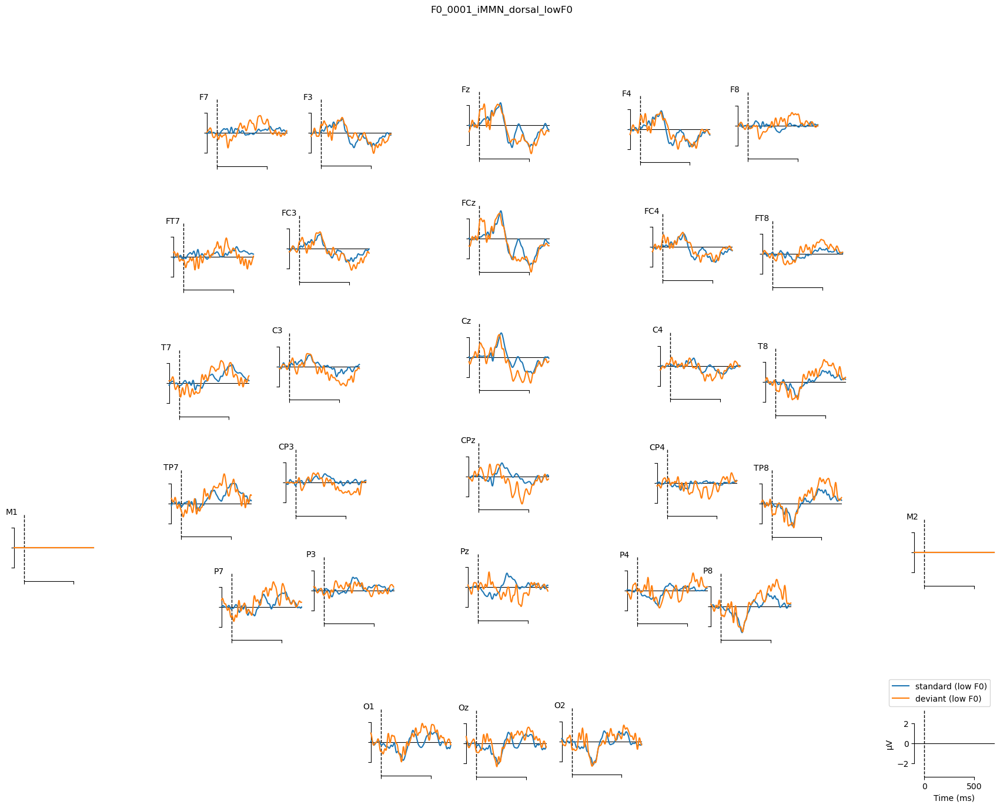

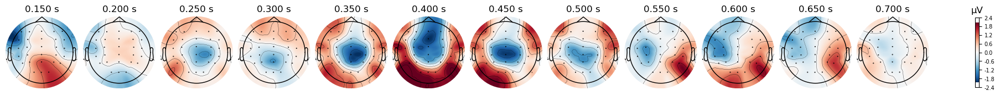

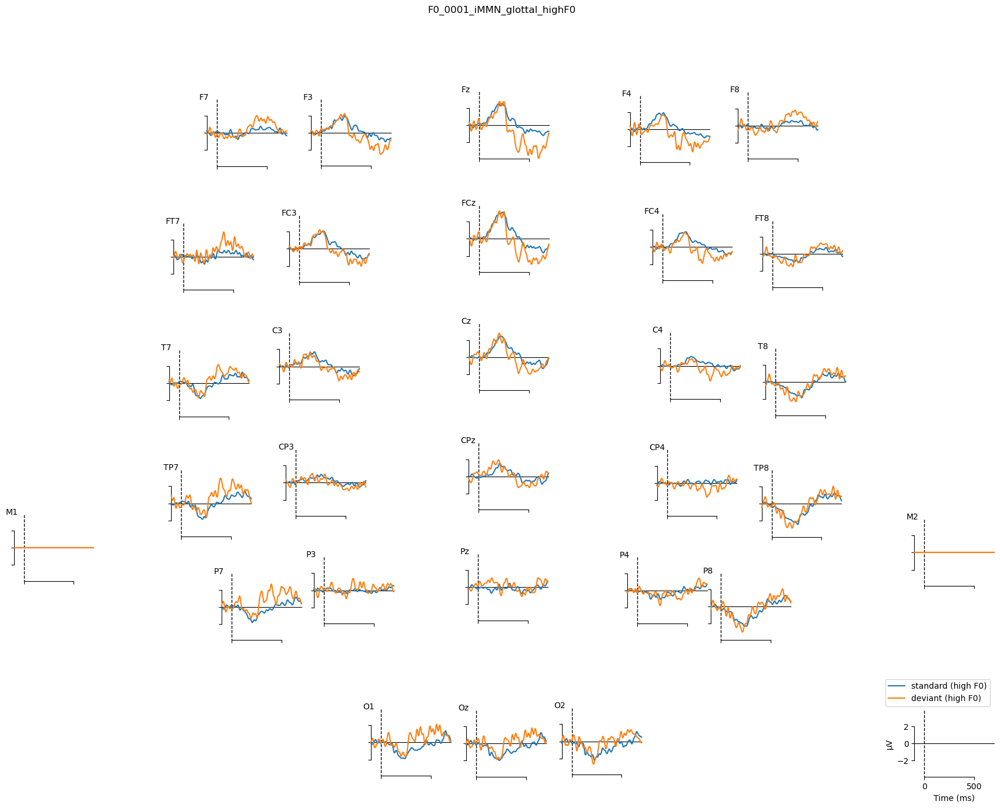

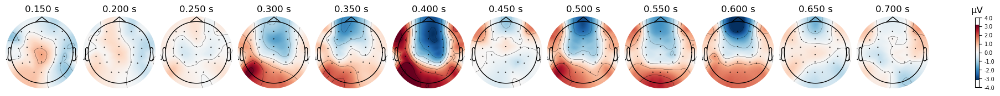

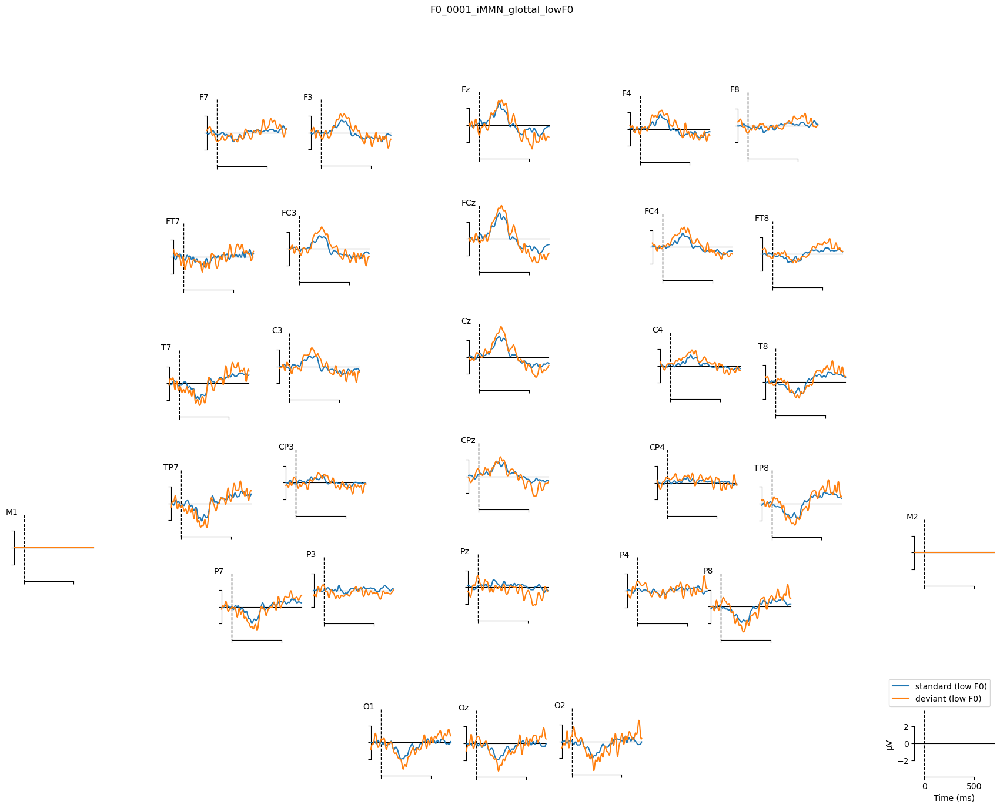

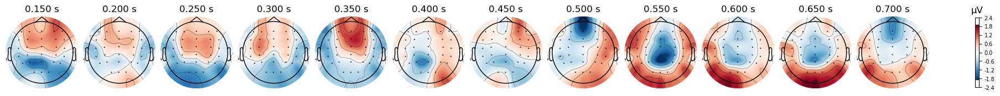

In [12]:
##### Seoul #####
# directory
input_dir = work_dir + 'Seoul Data/eeg_preprocessed/5_evokeds/'
# participant
ppt = 'F0_0001'
# plot
myfunc_single_ppt_plot(input_dir, ppt)

In [3]:
# times to show in topoplots (in seconds)
times = [0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]

##### function #####
def myfunc_single_ppt_plot(input_dir, ppt):

    # get group and file info
    file = ppt + '_ave.fif'
    group = ppt.split('_')[0]

    # plot
    for cell in cell_dict[group].keys():
        
        # get erp
        erp_stan = mne.read_evokeds(fname=input_dir+file, condition=cell_dict[group][cell]['stan'], verbose='WARNING')
        erp_devi = mne.read_evokeds(fname=input_dir+file, condition=cell_dict[group][cell]['devi'], verbose='WARNING')
        erp_diff = mne.combine_evoked([erp_devi, erp_stan], weights=[1,-1])
        
        # get legends
        legend_stan = 'standard (' + cell_dict[group][cell]['stan_stim'] + ')'
        legend_devi = 'deviant (' + cell_dict[group][cell]['devi_stim'] + ')'
        # legend_diff = 'deviants minus standards'
        
        
        ##########################
        ####  ERP Topographical subplot and ROI waveforms ####
        ##########################
        
        
        # combine data for plotting
        evokeds = {}
        evokeds[legend_stan] = erp_stan.filter(l_freq=None, h_freq=30, verbose='WARNING')
        evokeds[legend_devi] = erp_devi.filter(l_freq=None, h_freq=30, verbose='WARNING')
        # evokeds[legend_diff] = erp_diff.filter(l_freq=None, h_freq=30)
        
        
        
        ################################
        #### Topographical subplots ####
        ################################
        
        # figure title for the waveform
        title = ppt + '_' + cell
        
        ##############################
        # waveforms across scalp topo
        # NOTE: I don't know how to save these plots using the code
        fig = mne.viz.plot_compare_evokeds(
            evokeds,
            axes='topo',
            # picks=pick_chans,
            # combine="mean",
            show_sensors=True,
            # colors=colors,
            title = title,
            # ylim=dict(eeg=[-5, 5]),
            time_unit="ms",
            show=False,
        );
        # figure title for the waveform
        ##############################
        # waveforms across scalp topo
        # NOTE: I don't know how to save these plots using the code
    
        erp_diff.filter(l_freq=None, h_freq=30, verbose='WARNING').plot_topomap(times)
        ##### function end #####

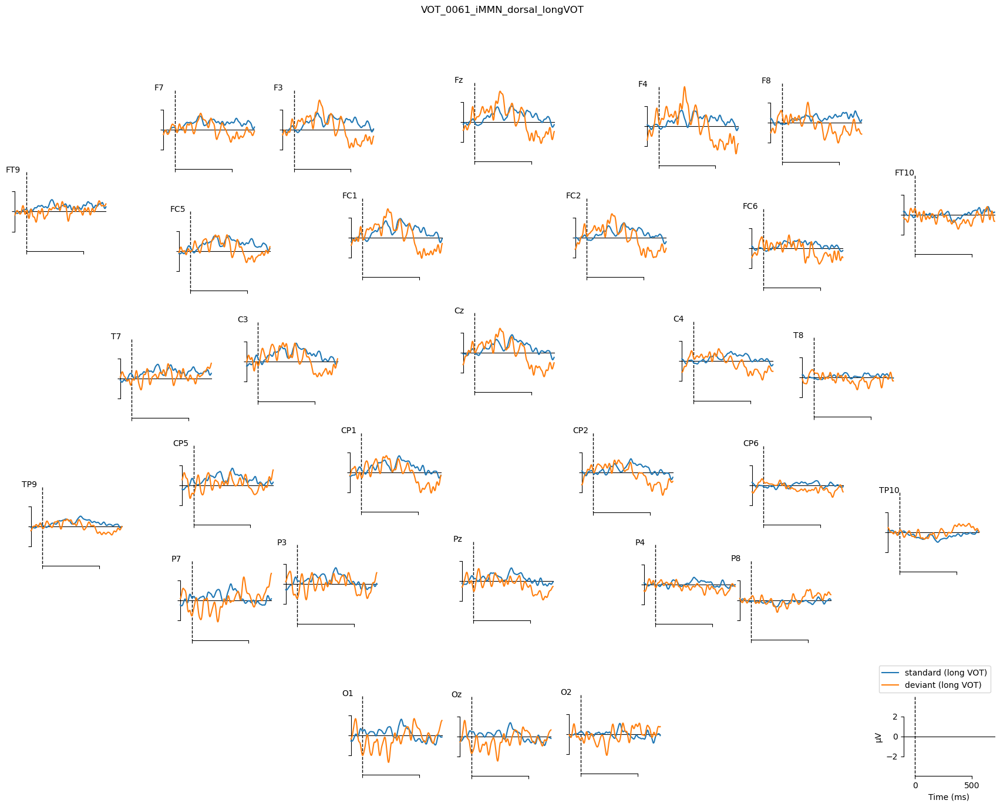

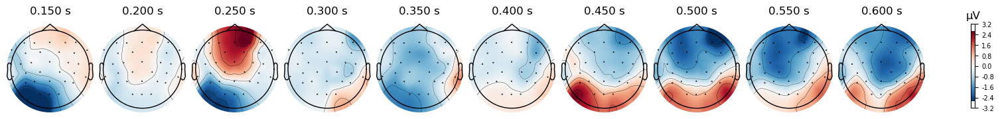

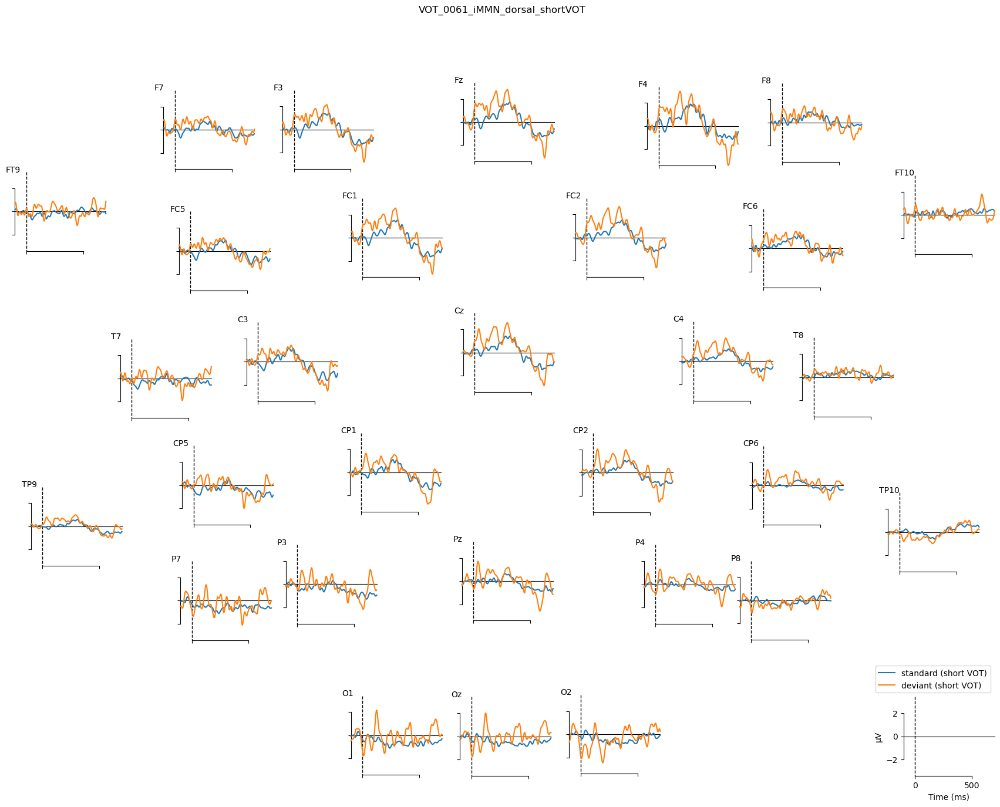

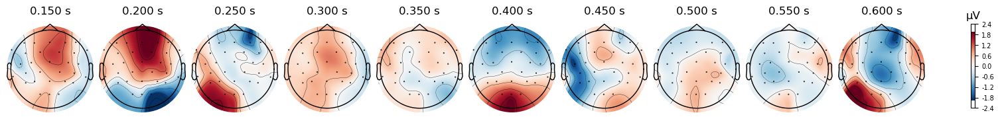

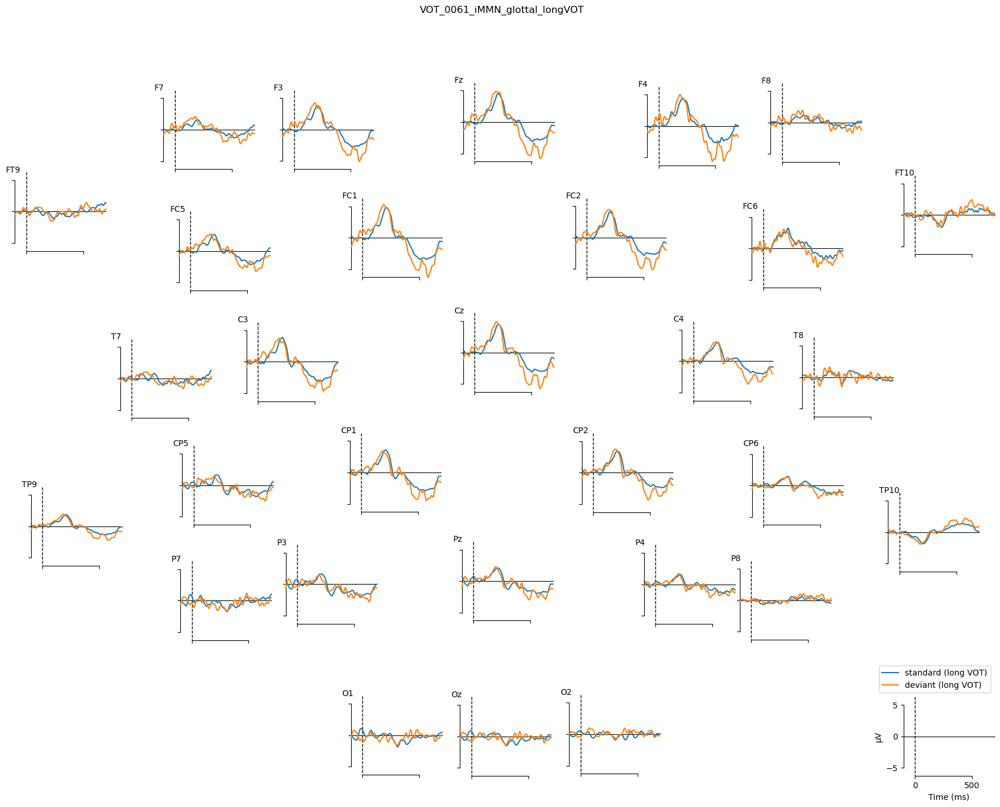

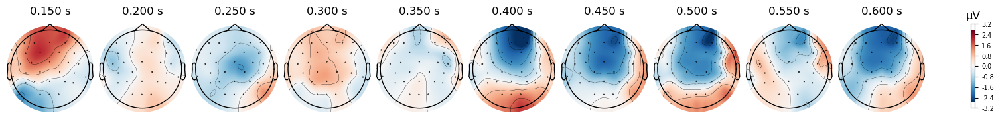

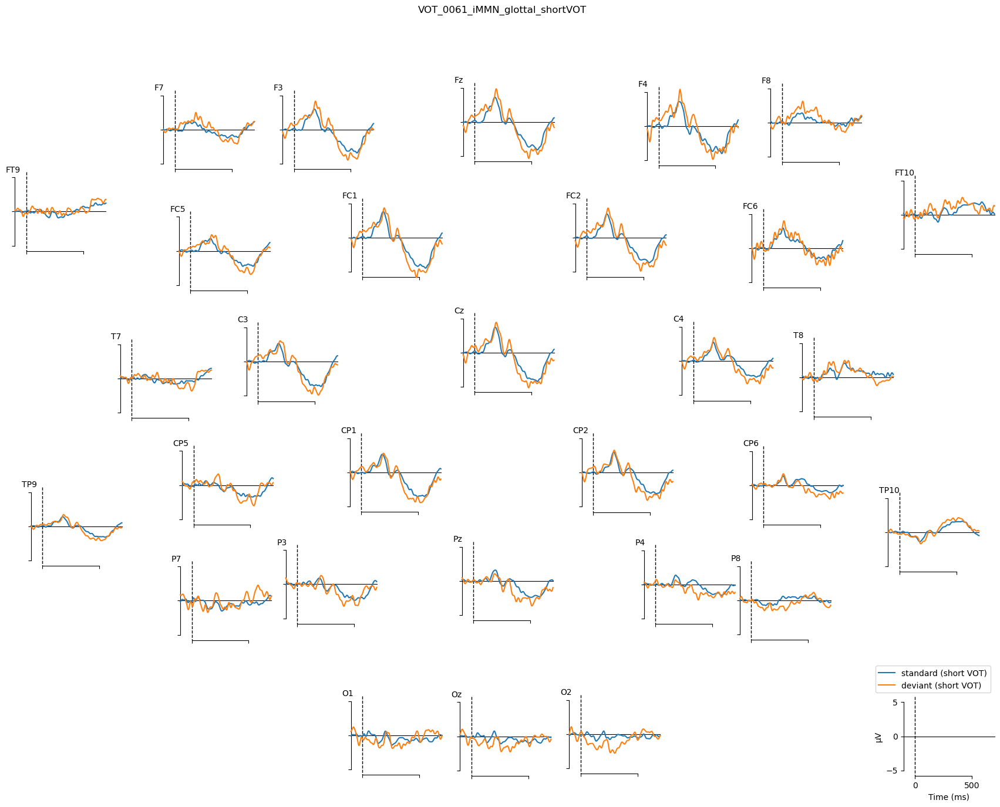

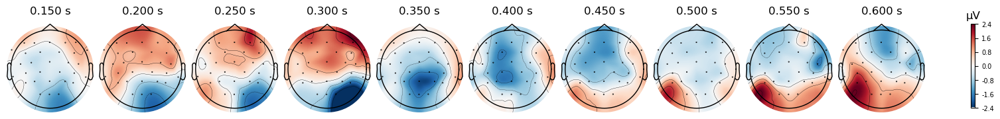

In [10]:
##### Toronto #####
# directory
input_dir = work_dir + 'data_preprocessed/5_evokeds/'
# participant
ppt = 'VOT_0061'
# plot
myfunc_single_ppt_plot(input_dir, ppt)

# Grand-average visualization

In [3]:
# save the plot?
toggle_save_plot = False
# toggle_save_plot = True

# times to show in topoplots (in seconds)
times = [0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]

# grand-average plot function
def myfunc_grand_average_plot():
        
    # figure title for the waveform
    waveform_title = group + ' group, ' + cell + ' (n = ' + str(len(subset_files)) + ')'

    wave, ax = plt.subplots(1, 1, figsize=(9, 6))
    
    mne.viz.plot_compare_evokeds(
        evokeds,
        axes=ax,
        picks=pick_chans,
        combine="mean",
        show_sensors=True,
        # colors=colors,
        title = waveform_title,
        # ylim=dict(eeg=[-5, 5]),
        time_unit="s",
        show=False
    )
    
    # # save fig
    # if toggle_save_plot:
    #     wave.savefig(output_dir + '/wave_' + group + '_' + cell +'.png')
    
    
    #### topomap of difference wave (deviants minus standards) ####
    
    #### plotting topo ####
    topo = grand_avg_diff.plot_topomap(
        ch_type="eeg", 
        times=times, 
        colorbar=True,
        vlim = (-1.5,1.5)
    )
        
    # # save fig
    # if toggle_save_plot:
    #     topo.savefig(output_dir + '/topo_' + group + '_' + cell +'.png')

## Toronto data

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/5_evokeds/F0_0001_ave.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms (dorsal_highStan_lowDevi_stan)
        0 CTF compensation matrices available
        nave = 335 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
Loaded Evoked data is baseline-corrected (baseline: [-0.1, 0] s)
Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


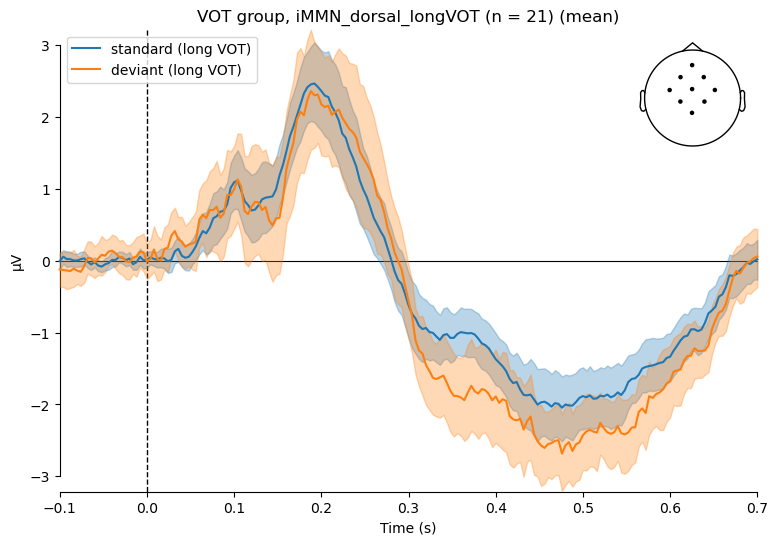

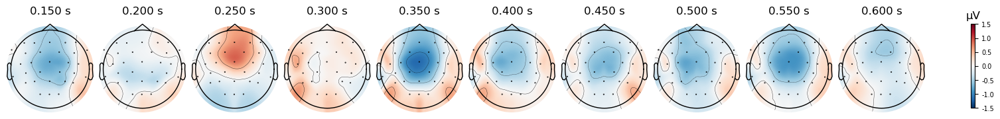

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


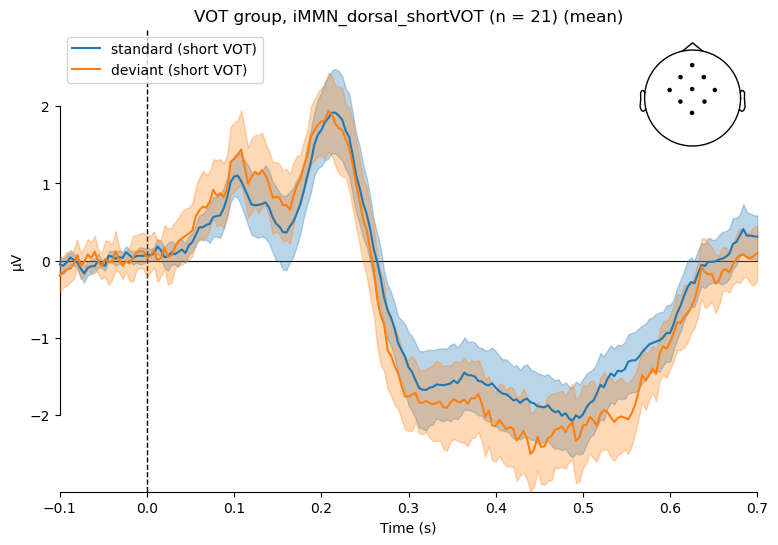

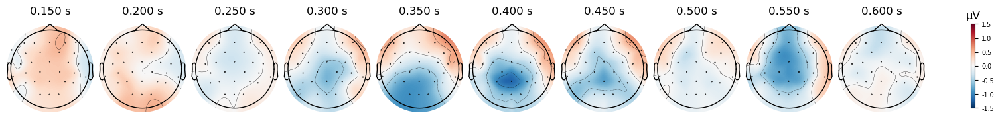

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


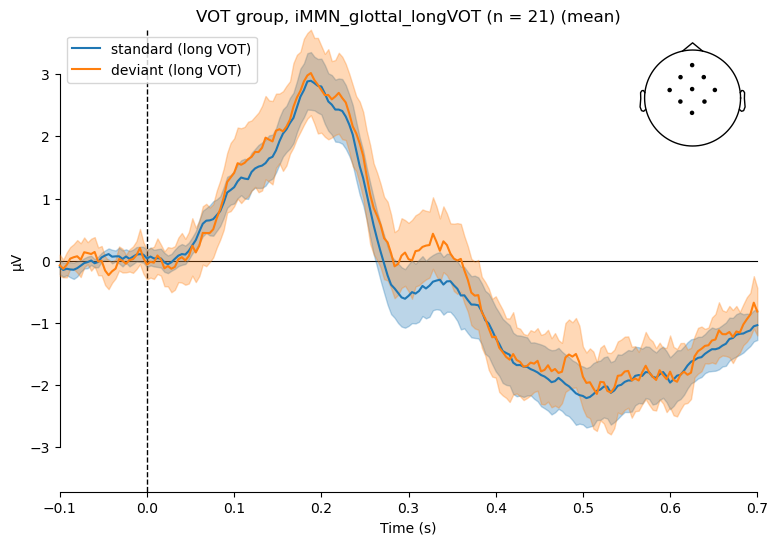

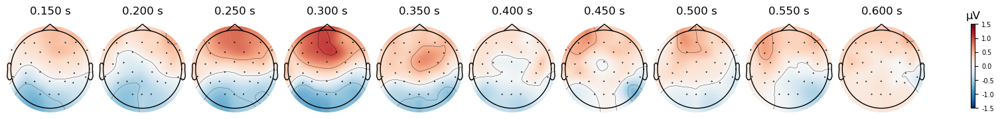

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


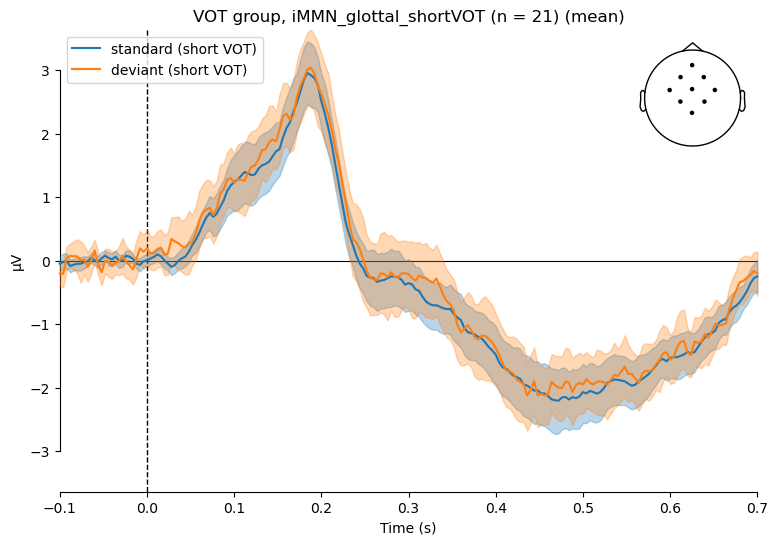

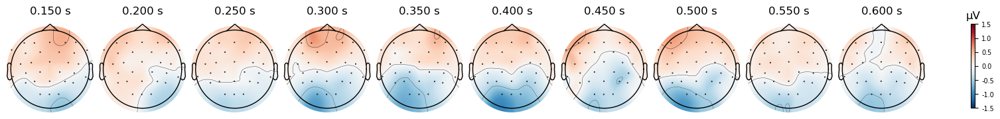

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


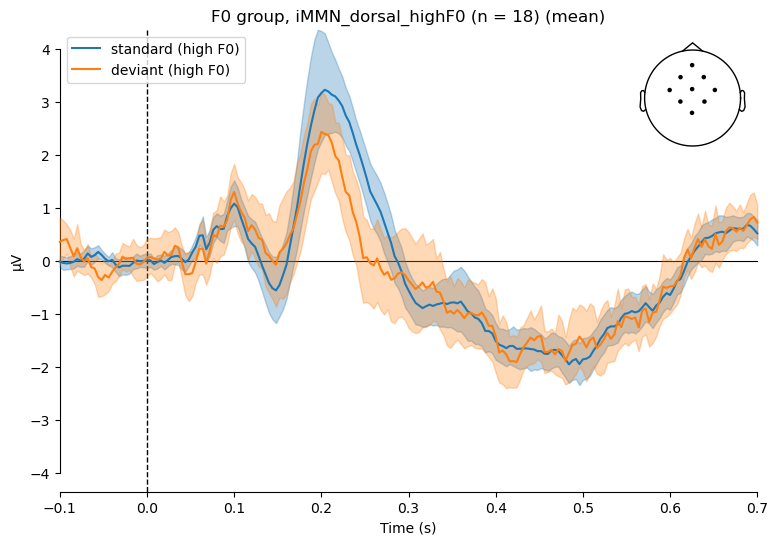

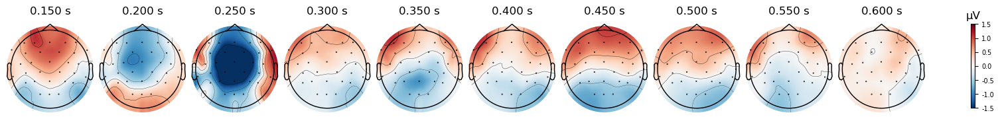

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


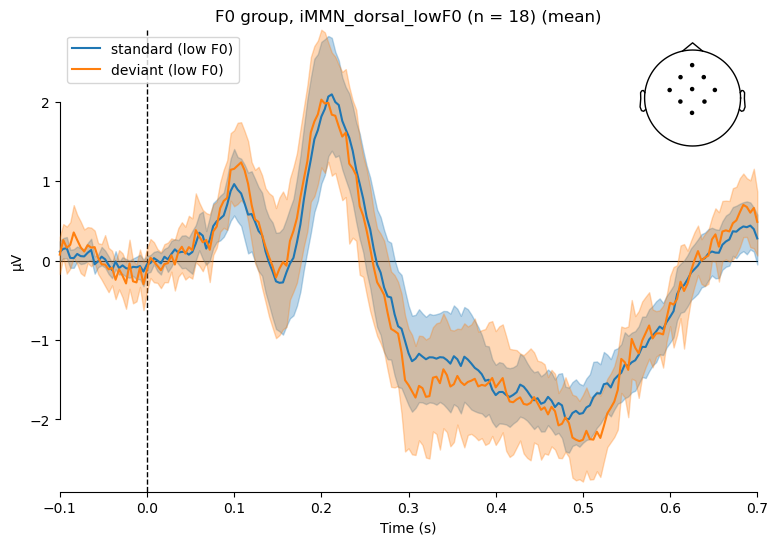

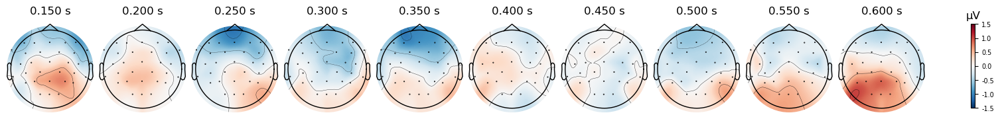

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


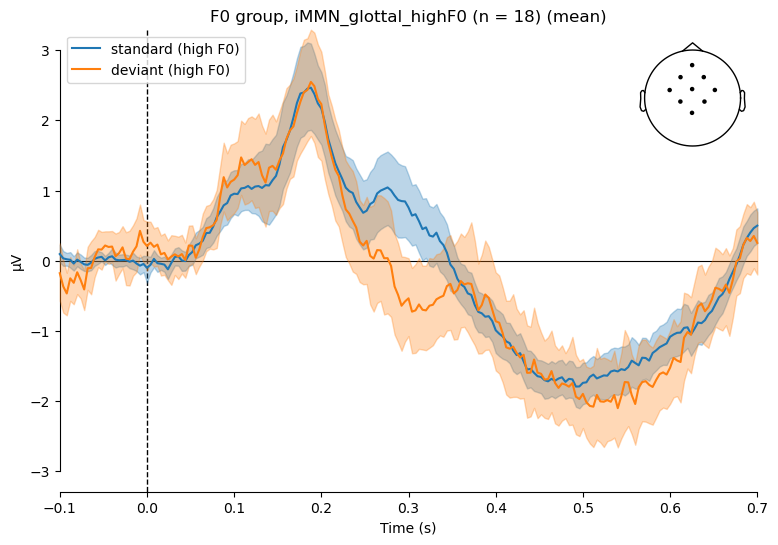

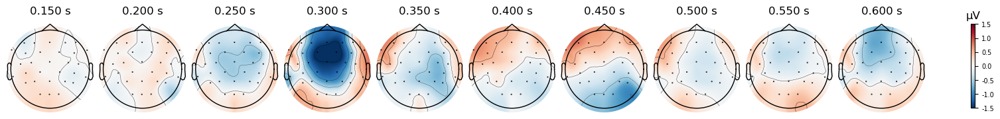

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


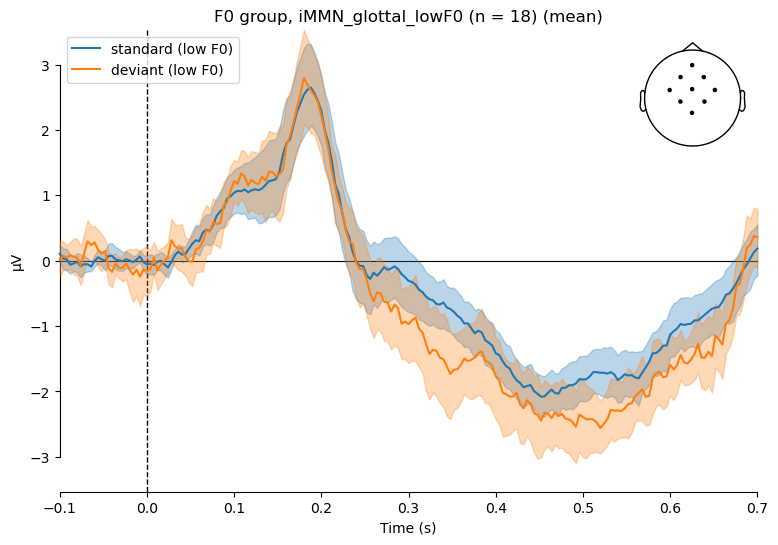

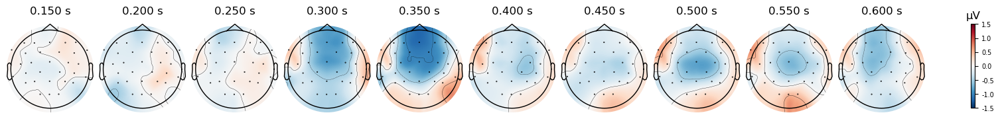

In [13]:
# directory
input_dir = work_dir + 'data_preprocessed/5_evokeds/'
all_inputs = os.listdir(input_dir)

# participants to exclude
exclude_ppts = [
]

# read in participant file
df = pd.read_csv(work_dir + 'data_analysis/participants_include.txt', delimiter = '\t')
include_ppts = df[df['include']==1]['participant'].astype(str).tolist()

# get time and channel info from any evoked data
evoked = mne.read_evokeds(fname=input_dir+'F0_0001_ave.fif', condition='dorsal_highStan_lowDevi_stan')
# time_labels = [str(int(x)) for x in evoked.times*1000]
chan_labels = evoked.ch_names
# choose a channel(s) for ERP plot
pick_chans = ['Cz', 'Fz', 'FC1', 'FC2', 'CP1', 'CP2', 'C3', 'C4', 'Pz']
# pick_chans = ['Cz']
# pick_chans = ['Cz', 'Fz', 'Pz']

# get channel index
ch_inds = np.isin(chan_labels, pick_chans)



##############################
##############################

# initialize dataframe for R plotting
df = pd.DataFrame()

# for each group
for group in ['VOT', 'F0']:
    
    # get participant list
    subset_files = []
    for file in all_inputs:
        if file.endswith('.fif') and (file.split('_')[0] in group) and (file.rsplit('_',1)[0] in include_ppts) and (file.rsplit('_',1)[0] not in exclude_ppts):
            # append that subject to the list
            subset_files.append(file)

    # for each cell
    for cell in cell_dict[group].keys():
        
        # get legends
        legend_stan = 'standard (' + cell_dict[group][cell]['stan_stim'] + ')'
        legend_devi = 'deviant (' + cell_dict[group][cell]['devi_stim'] + ')'
        # legend_diff = 'deviants minus standards'
        
        # extract ERPs
        # initialize list
        erp_stan = []
        erp_devi = []
        erp_diff = []
    
        # for each file
        for file in subset_files:

            # standard erp
            tmp_stan = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['stan'], verbose='WARNING')
            # deviant erp
            tmp_devi = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['devi'], verbose='WARNING')
            # compute temporary difference erp
            tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                          weights=[1,-1])

            ##### extract data for R plotting #####            
            # append
            tmp_erp = tmp_stan
            tmp_df = tmp_erp.to_data_frame(time_format='ms')
            tmp_df['group'] = group
            tmp_df['participant'] = file.rsplit('_',1)[0]
            tmp_df['condition'] = tmp_erp.comment
            # row bind data
            df = pd.concat([df, tmp_df])

            tmp_erp = tmp_devi
            tmp_df = tmp_erp.to_data_frame(time_format='ms')
            tmp_df['group'] = group
            tmp_df['participant'] = file.rsplit('_',1)[0]
            tmp_df['condition'] = tmp_erp.comment
            # row bind data
            df = pd.concat([df, tmp_df])

            tmp_erp = tmp_diff
            tmp_df = tmp_erp.to_data_frame(time_format='ms')
            tmp_df['group'] = group
            tmp_df['participant'] = file.rsplit('_',1)[0]
            tmp_df['condition'] = tmp_erp.comment
            # row bind data
            df = pd.concat([df, tmp_df])
            #######################################

            
            # append temporary data to list
            erp_stan.append(tmp_stan)
            erp_devi.append(tmp_devi)
            erp_diff.append(tmp_diff)
    
        # compute grand average of difference waves
        grand_avg_diff = mne.grand_average(erp_diff)
        
        # combine data for plotting
        evokeds = {}
        evokeds[legend_stan] = erp_stan
        evokeds[legend_devi] = erp_devi
        # evokeds[legend_diff] = erp_diff
   
        # plot
        myfunc_grand_average_plot()

# save
# df.to_csv(work_dir + 'presentations/SNL/figures/' + 'erp_all.txt', sep='\t', index=False)

## Seoul data

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/Seoul Data/eeg_preprocessed/5_evokeds/F0_0001_ave.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms (dorsal_highStan_lowDevi_stan)
        0 CTF compensation matrices available
        nave = 390 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
Loaded Evoked data is baseline-corrected (baseline: [-0.1, 0] s)
Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


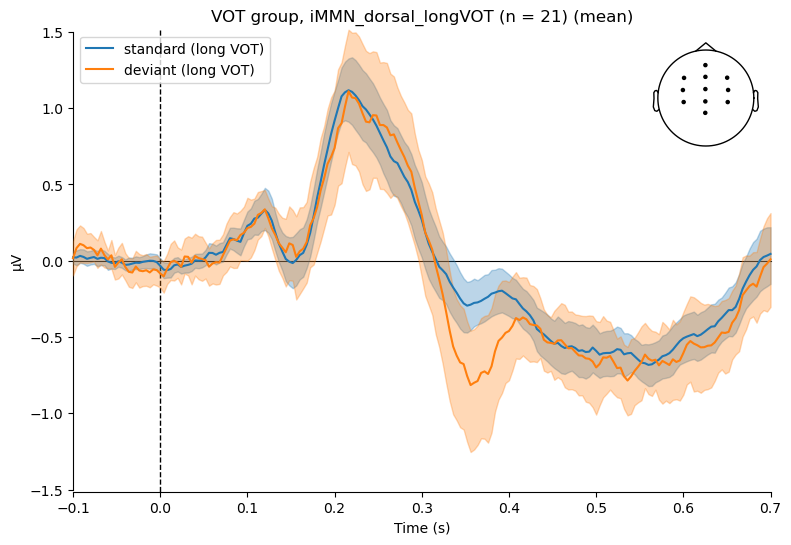

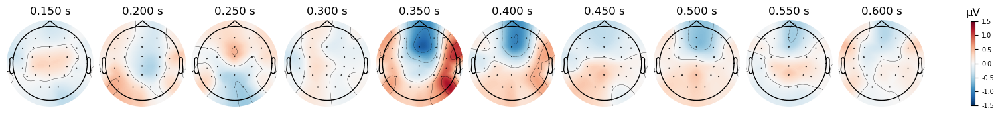

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


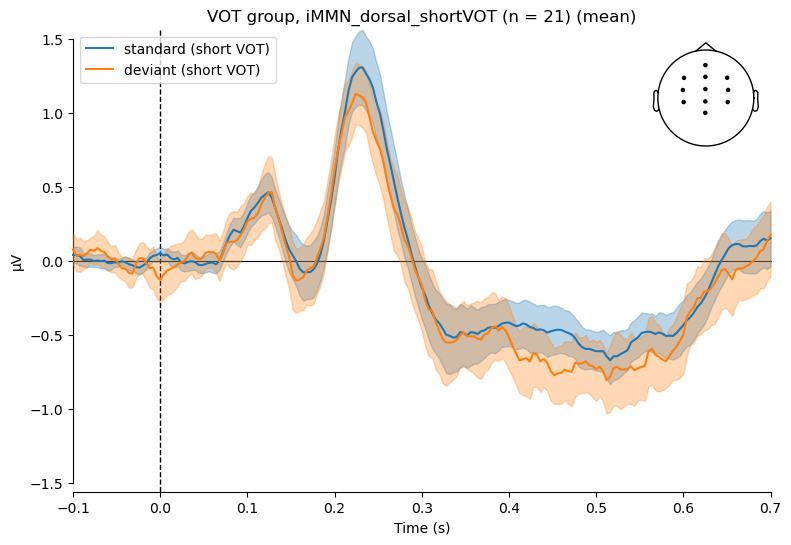

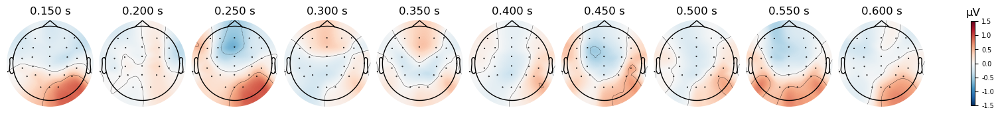

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


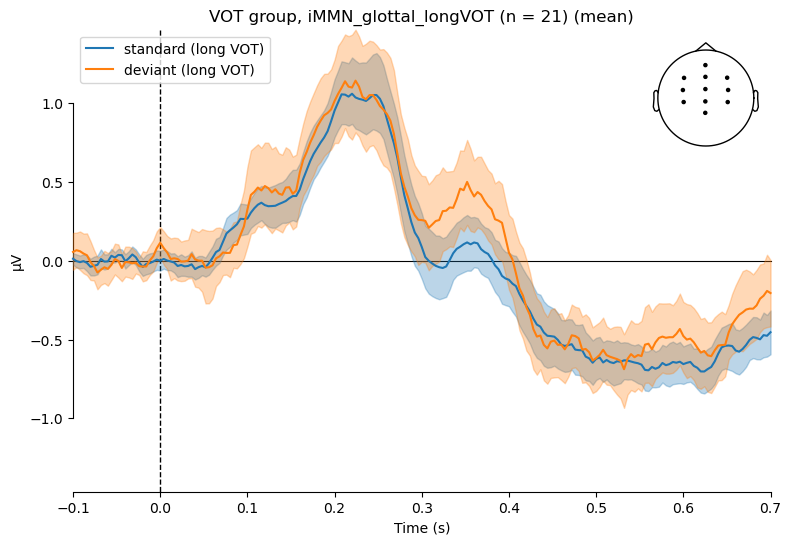

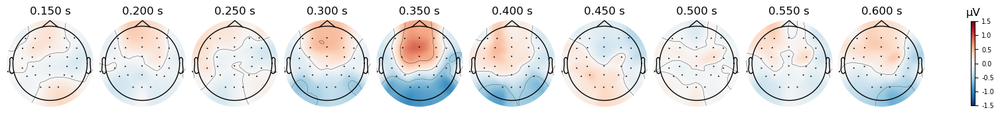

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


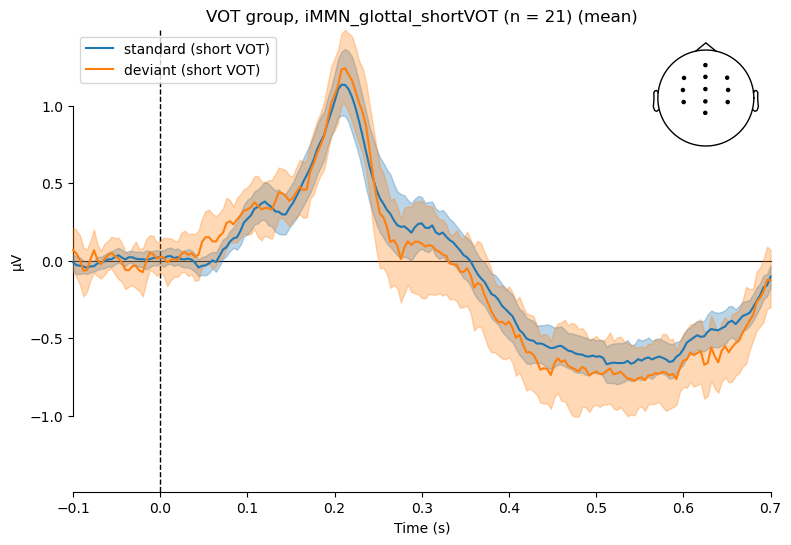

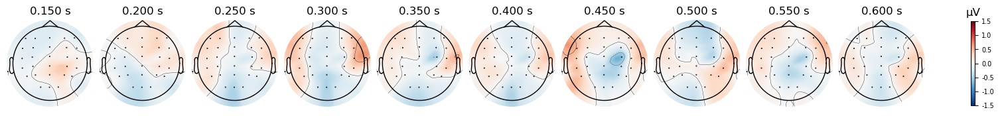

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


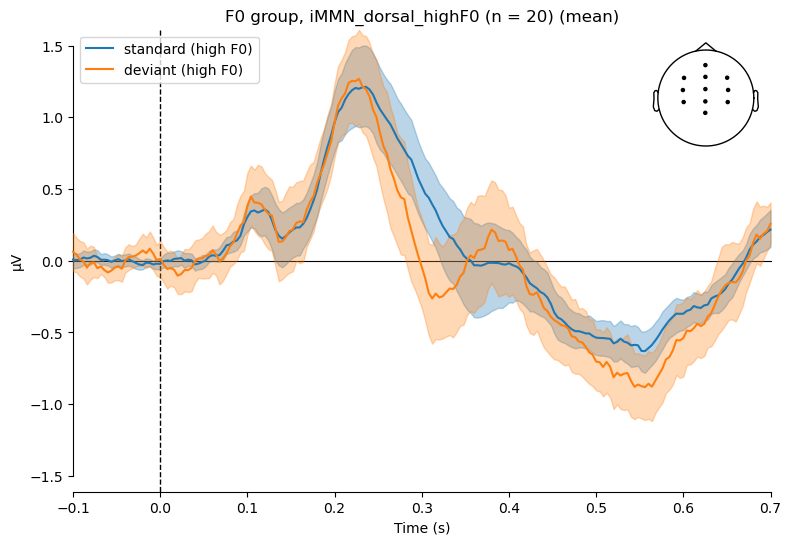

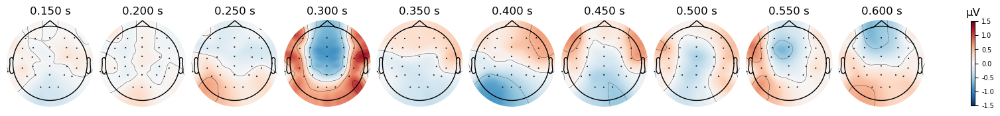

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


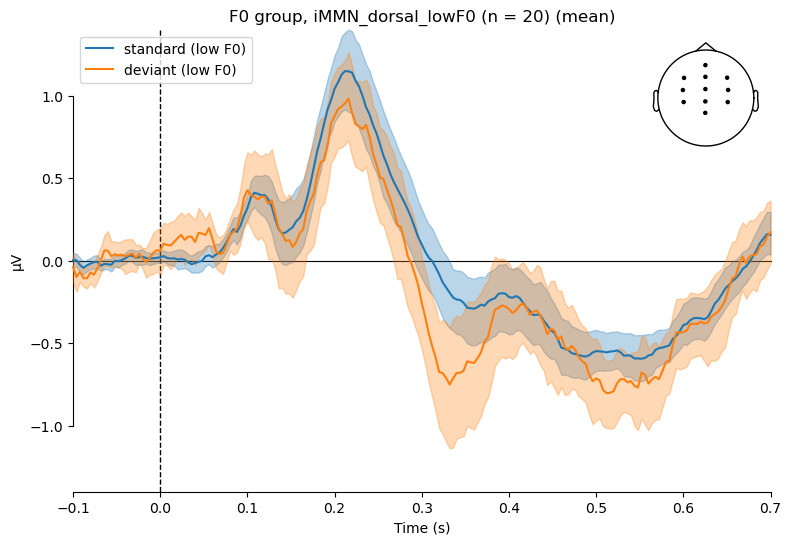

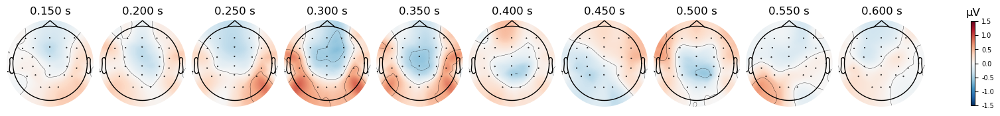

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


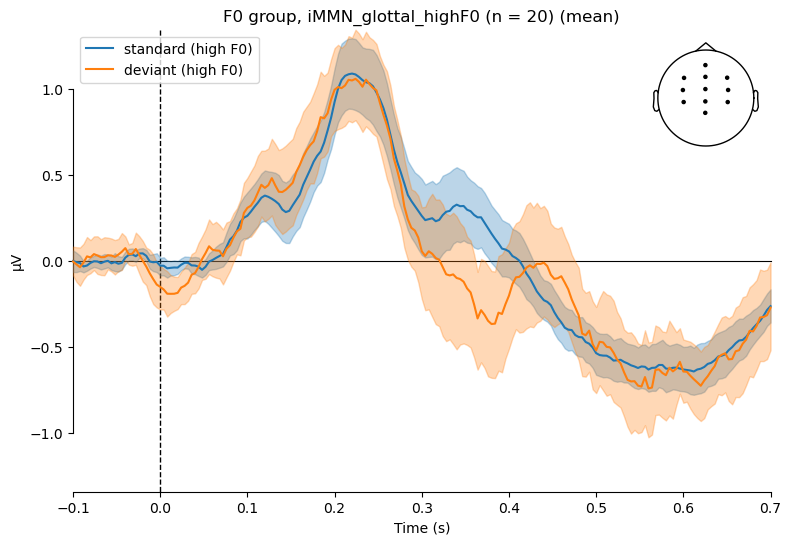

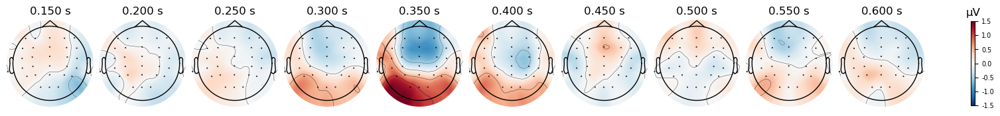

Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


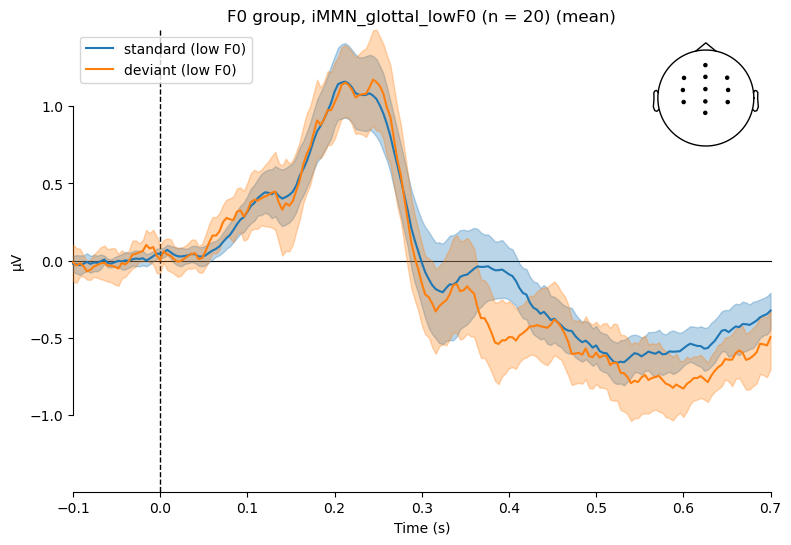

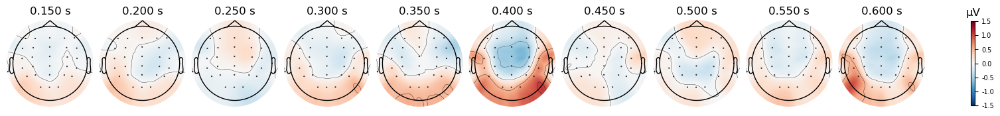

In [27]:
# participants to exclude
exclude_ppts = [
]

# directory
input_dir = work_dir + 'Seoul Data/eeg_preprocessed/5_evokeds/'
all_inputs = os.listdir(input_dir)

# get time and channel info from any evoked data
evoked = mne.read_evokeds(fname=input_dir+'F0_0001_ave.fif', condition='dorsal_highStan_lowDevi_stan')
# time_labels = [str(int(x)) for x in evoked.times*1000]
chan_labels = evoked.ch_names
# choose a channel(s) for ERP plot
pick_chans = ['Cz', 'FC3', 'FC4', 'FCz', 'Fz', 'C3', 'C4', 'CP3', 'CPz', 'CP4', 'Pz']
# pick_chans = ['Cz']

# get channel index
ch_inds = np.isin(chan_labels, pick_chans)

##############################
##############################
# for each group
for group in ['VOT', 'F0']:
    
    # get participant list
    subset_files = []
    for file in all_inputs:
        if file.endswith('.fif') and (file.split('_')[0] in group) and (file.rsplit('_',1)[0] not in exclude_ppts):
            # append that subject to the list
            subset_files.append(file)

    # for each cell
    for cell in cell_dict[group].keys():
        
        # get legends
        legend_stan = 'standard (' + cell_dict[group][cell]['stan_stim'] + ')'
        legend_devi = 'deviant (' + cell_dict[group][cell]['devi_stim'] + ')'
        # legend_diff = 'deviants minus standards'
        
        # extract ERPs
        # initialize list
        erp_stan = []
        erp_devi = []
        erp_diff = []
    
        # for each file
        for file in subset_files:

            # standard erp
            tmp_stan = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['stan'], verbose='WARNING')
            # deviant erp
            tmp_devi = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['devi'], verbose='WARNING')
            # compute temporary difference erp
            tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                          weights=[1,-1])
            # append temporary data to list
            erp_stan.append(tmp_stan)
            erp_devi.append(tmp_devi)
            erp_diff.append(tmp_diff)
    
        # compute grand average of difference waves
        grand_avg_diff = mne.grand_average(erp_diff)
        
        # combine data for plotting
        evokeds = {}
        evokeds[legend_stan] = erp_stan
        evokeds[legend_devi] = erp_devi
        # evokeds[legend_diff] = erp_diff
   
        # plot
        myfunc_grand_average_plot()

# Spatiotemporal permutation

In [24]:
# save the plot?
toggle_save_plot = False
# toggle_save_plot = True

######### permutation function ##########
def myfunc_permutation(erp_diff):
    
    # extract data for stats
    X = np.stack([x.get_data() for x in erp_diff], axis=0)
    # reshape the data for stats analysis
    X = np.transpose(X, [0, 2, 1]) # output: participant x time x channel
    
    # print(X.shape)
    
    ###################################
    #### cluster-based permutation ####
    ###################################
    
    # Here we set a cluster forming threshold based on a p-value for
    # the cluster based permutation test.
    # We use a two-tailed threshold, the "1 - p_threshold" is needed
    # because for two-tailed tests we must specify a positive threshold.
    p_thresh = 0.05  # arbitrary
    n_observations = X.shape[0]
    df = n_observations - 1  # degrees of freedom for the test
    
    # two-tailed test
    tail = 0
    t_thresh = scipy.stats.t.ppf(1 - p_thresh / 2, df)
    
    # one tail, 1 for higher tail, -1 for lower tail
    # tail = -1
    # t_thresh = scipy.stats.t.ppf(p_thresh, df)
    
    
    # Run the analysis
    T_obs, clusters, cluster_p_values, H0 = mne.stats.spatio_temporal_cluster_1samp_test(
        X,
        adjacency=adjacency,
        threshold=t_thresh,
        tail=tail,
        # out_type="mask",
        seed = 1 # set random seed
    )
    
    #########################
    #### select clusters ####
    #########################
    
    # Select the clusters that are statistically significant at p < 0.05
    p_accept = 0.05
    good_clusters_idx = np.where(cluster_p_values < p_accept)[0]

    return good_clusters_idx, clusters, T_obs
################################################


######### permutation plot data extract function ##########
def myfunc_permutation_plot():

    # unpack cluster information, get unique indices
    time_inds, space_inds = np.squeeze(clusters[good_clusters_idx[ith_cluster]])

    # get unique channel and time indices
    ch_inds = np.unique(space_inds)
    print(np.array(evoked.ch_names)[ch_inds])
    time_inds = np.unique(time_inds)             
    
    # get topography for F stat
    t_map = T_obs[time_inds, ...].mean(axis=0)

    # get signals at the sensors contributing to the cluster
    sig_times = evoked.times[time_inds]
    print(round(sig_times[0]*1000), round(sig_times[-1]*1000))

    # create spatial mask
    mask = np.zeros((t_map.shape[0], 1), dtype=bool) # the number is obtained based on the error message, I don't know how to decide this number.
    mask[ch_inds, :] = True

    # initialize figure
    fig, ax_topo = plt.subplots(1, 1, figsize=(10, 10), layout="constrained")

    # plot topos of average test statistic and mark significant sensors
    t_evoked = mne.EvokedArray(t_map[:, np.newaxis]/1e6, evoked.info, tmin=0)
    t_evoked.plot_topomap(
        times=0,
        mask=mask,
        axes=ax_topo,
        # cmap="jet",
        vlim=(np.min, np.max),
        show=False,
        colorbar=False,
        mask_params=dict(markersize=10),
    )
    image = ax_topo.images[0]

    # remove the title that would otherwise say "0.000 s"
    ax_topo.set_title("")

    # create additional axes (for ERF and colorbar)
    divider = make_axes_locatable(ax_topo)

    # add axes for colorbar
    ax_colorbar = divider.append_axes("right", size="5%", pad=0.05)
    plt.colorbar(image, cax=ax_colorbar)
    ax_topo.set_xlabel(
        "Averaged t-map ({:}-{:}ms)".format(round(sig_times[0]*1000), round(sig_times[-1]*1000))
    )

    # add new axis for time courses and plot time courses
    ax_signals = divider.append_axes("right", size="200%", pad=1.2)

    # plot waveforms
    mne.viz.plot_compare_evokeds(
        evokeds,
        title=permutation_wave_title,
        picks=ch_inds,
        axes=ax_signals,
        # colors=colors,
        # linestyles=linestyles,
        show=False,
        split_legend=True,
        truncate_yaxis="auto",
        combine="mean",
    )
    
    # plot temporal cluster extent
    for t in sig_times:
        ax_signals.axvline(t, ymin=0.01, ymax=0.05, color="black", linewidth=1)

## Toronto Data

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/5_evokeds/F0_0001_ave.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms (dorsal_highStan_lowDevi_stan)
        0 CTF compensation matrices available
        nave = 335 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
Loaded Evoked data is baseline-corrected (baseline: [-0.1, 0] s)
Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28
stat_fun(H1): min=-4.353151025435771 max=4.434860814382104
Running initial clustering …
Found 58 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== VOT iMMN_dorsal_longVOT significant clusters =====
[]
stat_fun(H1): min=-6.051410616845547 max=5.8564300416674975
Running initial clustering …
Found 62 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== VOT iMMN_dorsal_shortVOT significant clusters =====
[51]
Identifying common channels ...
['FC1' 'C3' 'CP5' 'CP1' 'Pz' 'P3' 'P7' 'O1' 'Oz' 'O2' 'P4' 'P8' 'CP6'
 'CP2' 'Cz' 'C4']
308 464
combining channels using "mean"
combining channels using "mean"
stat_fun(H1): min=-6.133521176472165 max=5.72036418595797
Running initial clustering …
Found 87 clusters


...

===== F0 iMMN_dorsal_lowF0 significant clusters =====
[]
stat_fun(H1): min=-6.058951344257784 max=3.3767559241905594
Running initial clustering …
Found 59 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== F0 iMMN_glottal_highF0 significant clusters =====
[46]
Identifying common channels ...
['Fz' 'F3' 'FC5' 'FC1' 'C3' 'CP5' 'CP1' 'Pz' 'P3' 'P4' 'CP6' 'CP2' 'Cz'
 'C4' 'FC6' 'FC2' 'F4']
244 344
combining channels using "mean"
combining channels using "mean"
stat_fun(H1): min=-5.945313238778654 max=3.7228958950531554
Running initial clustering …
Found 61 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== F0 iMMN_glottal_lowF0 significant clusters =====
[]


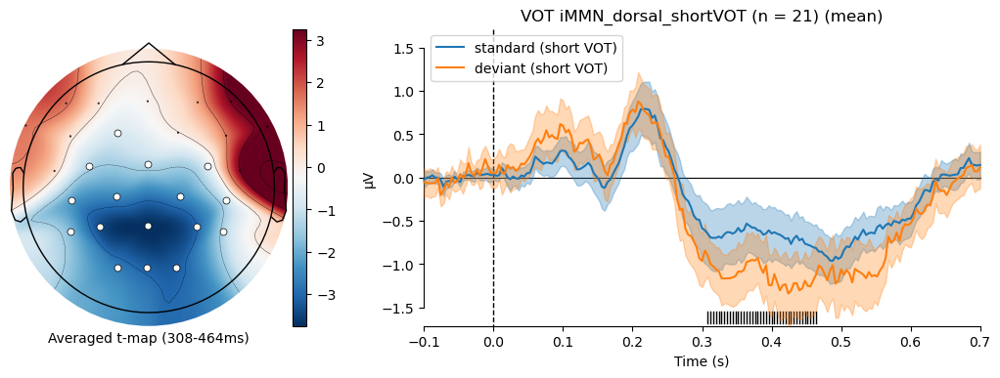

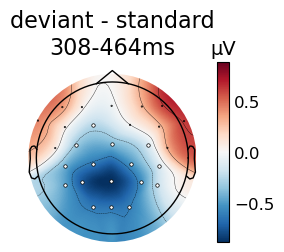

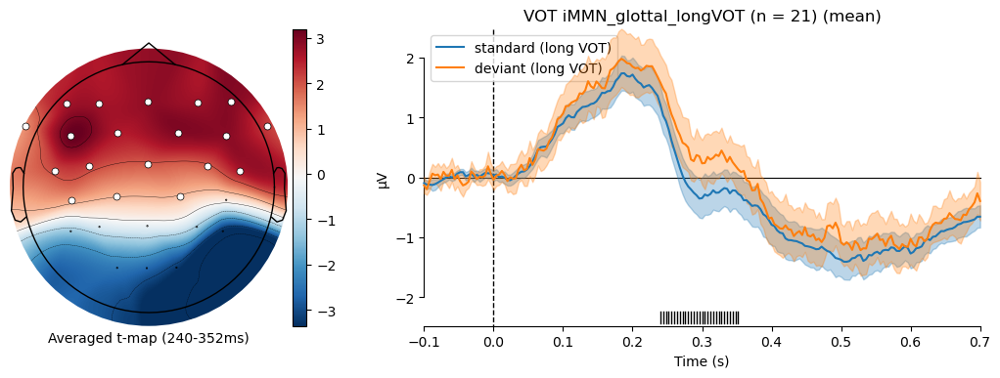

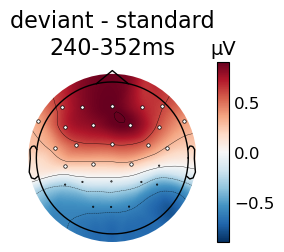

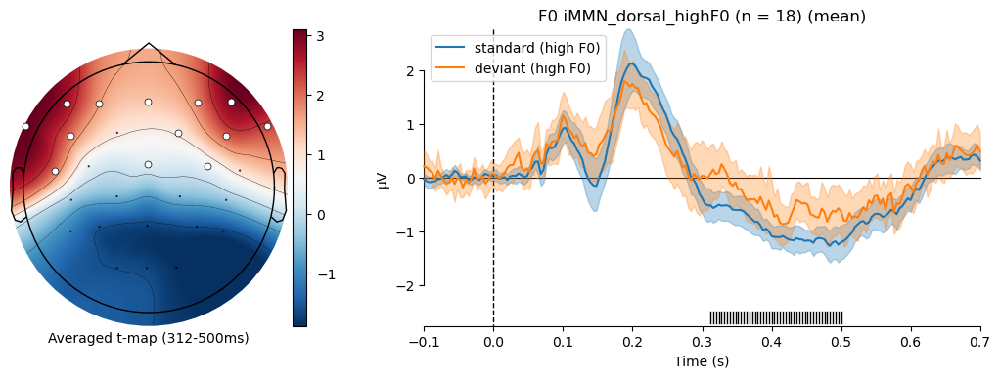

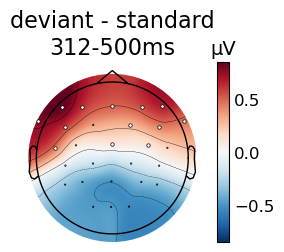

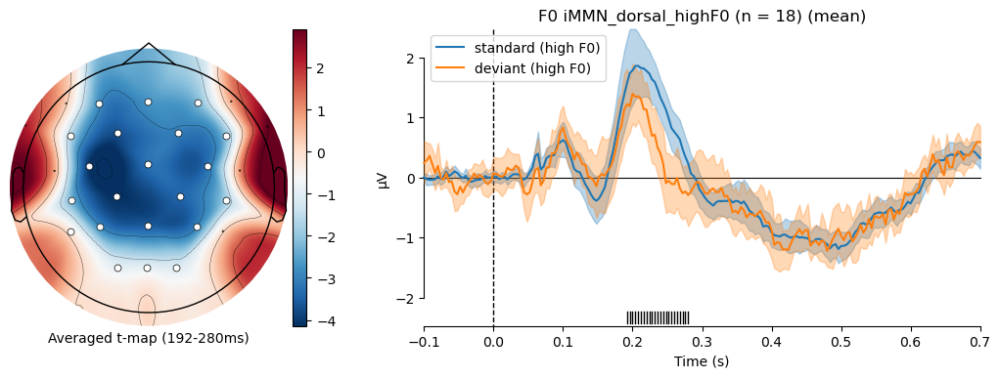

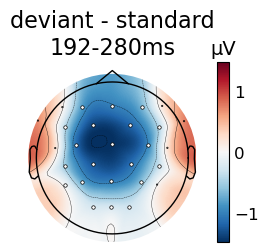

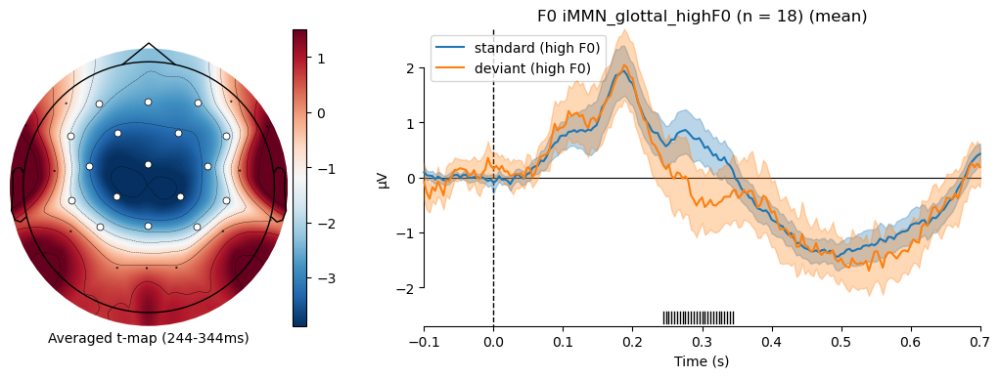

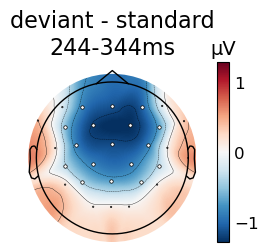

In [42]:
# read in participant file
df = pd.read_csv(work_dir + 'data_analysis/participants_include.txt', delimiter = '\t')
include_ppts = df[df['include']==1]['participant'].astype(str).tolist()

ref_channels = ['TP9', 'TP10']

# directory
input_dir = work_dir + 'data_preprocessed/5_evokeds/'
# get time and channel info from any evoked data
evoked = mne.read_evokeds(fname=input_dir+'F0_0001_ave.fif', condition='dorsal_highStan_lowDevi_stan')
evoked.drop_channels(ref_channels)
# channel adjacency
adjacency, chan_names = mne.channels.find_ch_adjacency(evoked.info, 'eeg')


all_inputs = os.listdir(input_dir)

# participants to exclude
exclude_ppts = [
]

# for each group
for group in ['VOT', 'F0']:

    # get participant list
    subset_files = []
    for file in all_inputs:
        if file.endswith('.fif') and (file.split('_')[0] in group) and (file.rsplit('_',1)[0] in include_ppts) and (file.rsplit('_',1)[0] not in exclude_ppts):
            # append that subject to the list
            subset_files.append(file)

    # for each cell
    for cell in cell_dict[group].keys():

        # initialize erp data
        erp_diff = []

        # extract ERPs
        # for each participant
        for file in subset_files:
        
            # standard erp
            tmp_stan = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['stan'], verbose='WARNING')
            tmp_stan.drop_channels(ref_channels)
            
            # deviant erp
            tmp_devi = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['devi'], verbose='WARNING')
            tmp_devi.drop_channels(ref_channels)
            
            # compute temporary difference erp
            tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                          weights=[1,-1])
            # append temporary data to list
            erp_diff.append(tmp_diff)
        
            del tmp_stan, tmp_devi, tmp_diff

        # apply function
        good_clusters_idx, clusters, T_obs = myfunc_permutation(erp_diff)

        print('===== ' + group + ' ' + cell + ' significant clusters =====')
        print(good_clusters_idx)
        
        ## visualize clusters

        #######################
        #### visualization ####
        #######################
        
        #### parameter ####
        toggle_save_plot = False
        
        if len(good_clusters_idx) > 0:

            # get plot title
            permutation_wave_title = group + ' ' + cell + ' (n = ' + str(len(subset_files)) + ')'

            # extract ERPs for each condition
            # for each cell

            # get legends
            legend_stan = 'standard (' + cell_dict[group][cell]['stan_stim'] + ')'
            legend_devi = 'deviant (' + cell_dict[group][cell]['devi_stim'] + ')'

            # initialize
            erp_stan = []
            erp_devi = []
            
            # for each participant
            for file in subset_files:
            
                # standard erp
                tmp_stan = mne.read_evokeds(input_dir + file, 
                                            condition=cell_dict[group][cell]['stan'], verbose='WARNING')
                tmp_stan.drop_channels(ref_channels)
                
                # deviant erp
                tmp_devi = mne.read_evokeds(input_dir + file, 
                                            condition=cell_dict[group][cell]['devi'], verbose='WARNING')
                tmp_devi.drop_channels(ref_channels)
        
                # compute temporary difference erp
                tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                              weights=[1,-1])
                # append temporary data to list
                erp_stan.append(tmp_stan)
                erp_devi.append(tmp_devi)
            
            # organize data for plotting
            evokeds = {
                legend_stan: erp_stan,
                legend_devi: erp_devi,
            }

            # prepare data for diff topo
            grand_avg_diff = mne.grand_average(erp_diff)
            
            # loop over clusters
            for ith_cluster in range(len(good_clusters_idx)):

                # apply plot function
                myfunc_permutation_plot()

                ############## for snl plot ##############
                # unpack cluster information, get unique indices
                time_inds, space_inds = np.squeeze(clusters[good_clusters_idx[ith_cluster]])
                # get unique channel and time indices
                ch_inds = np.unique(space_inds)
                time_inds = np.unique(time_inds)
                # plot
                figsize = (3,3)
                topo_position = [0.1, 0.1, 0.6, 0.6]
                colorbar_position = [0.75, 0.1, 0.04, 0.6]
                fig = plt.figure(figsize=figsize)
                ax_topo = fig.add_axes(topo_position)  # Main topomap
                ax_cb = fig.add_axes(colorbar_position)
                # create spatial mask
                mask = np.zeros(grand_avg_diff.data.shape, dtype=bool) 
                mask[ch_inds, :] = True
                grand_avg_diff.plot_topomap(
                    ch_type="eeg", 
                    axes=ax_topo,
                    times=evoked.times[int(time_inds[0]+(time_inds[-1]-time_inds[0])/2)],
                    average = (evoked.times[time_inds][-1]-evoked.times[time_inds][0]),
                    mask=mask,
                    mask_params=dict(markersize=5, markerfacecolor='w', markeredgecolor='k'),
                    size = 1,
                    show=False,
                    colorbar=False,
                    # vlim = (-0.8, 0.8),
                )
                sig_times = evoked.times[time_inds]
                ax_topo.set_title('deviant - standard\n{:}-{:}ms'.format(round(sig_times[0]*1000), round(sig_times[-1]*1000)), fontsize=16)
                # colorbar
                plt.colorbar(ax_topo.images[0], cax=ax_cb)
                ax_cb.set_title("μV", fontsize=14)
                ax_cb.tick_params(length=0, labelsize=12)
                fig.savefig('/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/presentations/SNL/figures/topo_'+group+'_'+cell+'_'+str(ith_cluster)+'.jpg', dpi=300, bbox_inches='tight')
                ############## for snl plot ##############

### blank topo

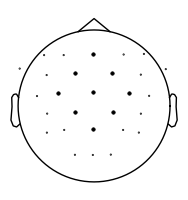

In [51]:
# blank topo
# create spatial mask
pick_chans = ['Cz', 'Fz', 'FC1', 'FC2', 'CP1', 'CP2', 'C3', 'C4', 'Pz']



topo_data = grand_avg_diff

# get channel index
ch_inds = np.isin(topo_data.ch_names, pick_chans)

topo_data.data = np.nan * np.ones_like(topo_data.data)

mask = np.zeros(topo_data.data.shape, dtype=bool) 
mask[ch_inds, :] = True

# plot
figsize = (3,3)
topo_position = [0.1, 0.1, 0.6, 0.6]
colorbar_position = [0.75, 0.1, 0.04, 0.6]
fig = plt.figure(figsize=figsize)
ax_topo = fig.add_axes(topo_position)  # Main topomap
# ax_cb = fig.add_axes(colorbar_position)

topo_data.plot_topomap(
    ch_type="eeg",
    axes=ax_topo,
    times=0,
    mask=mask,
    mask_params=dict(markersize=5, markerfacecolor='k', markeredgecolor='k'),
    size = 1,
    show=False,
    colorbar=False,
)
fig.axes[0].set_title('')

fig.savefig('/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/presentations/SNL/figures/topo_blank.jpg', dpi=300, bbox_inches='tight')

### collapse all conditions

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/5_evokeds/F0_0001_ave.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms (dorsal_highStan_lowDevi_stan)
        0 CTF compensation matrices available
        nave = 335 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
Loaded Evoked data is baseline-corrected (baseline: [-0.1, 0] s)
Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28
stat_fun(H1): min=-5.219213219827632 max=5.061271001445483
Running initial clustering …
Found 55 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== VOT significant clusters =====
[15 51]
['Fz' 'F3' 'F7' 'FT9' 'FC5' 'FC1' 'C3' 'T7' 'T8' 'FT10' 'FC6' 'FC2' 'F4'
 'F8']
combining channels using "mean"
combining channels using "mean"
['C3' 'CP5' 'CP1' 'Pz' 'P3' 'P7' 'O1' 'Oz' 'O2' 'P4' 'P8' 'CP2' 'Cz' 'C4']
combining channels using "mean"
combining channels using "mean"
stat_fun(H1): min=-5.288890844748113 max=4.34654594329575
Running initial clustering …
Found 56 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== F0 significant clusters =====
[42]
['Fz' 'F3' 'FC5' 'FC1' 'C3' 'CP5' 'CP1' 'Pz' 'P3' 'P7' 'Oz' 'O2' 'P4'
 'CP6' 'CP2' 'Cz' 'C4' 'FC6' 'FC2' 'F4']
combining channels using "mean"
combining channels using "mean"


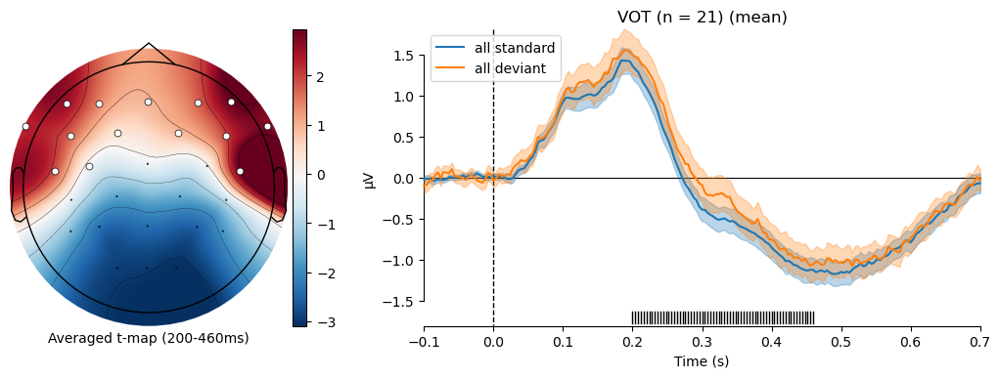

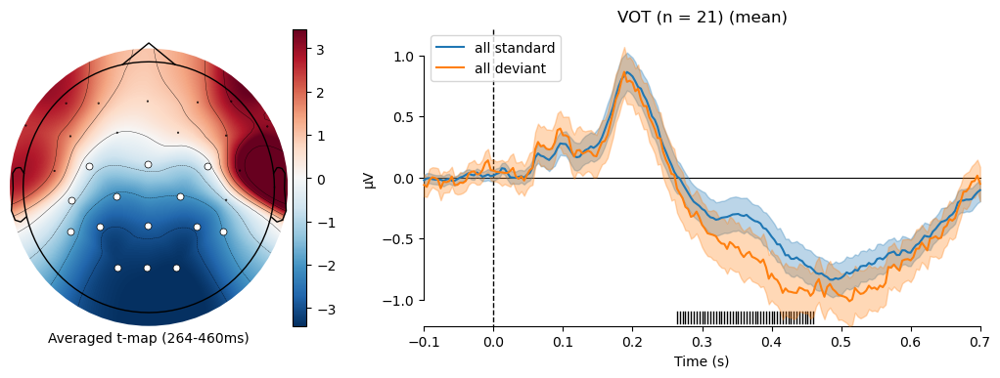

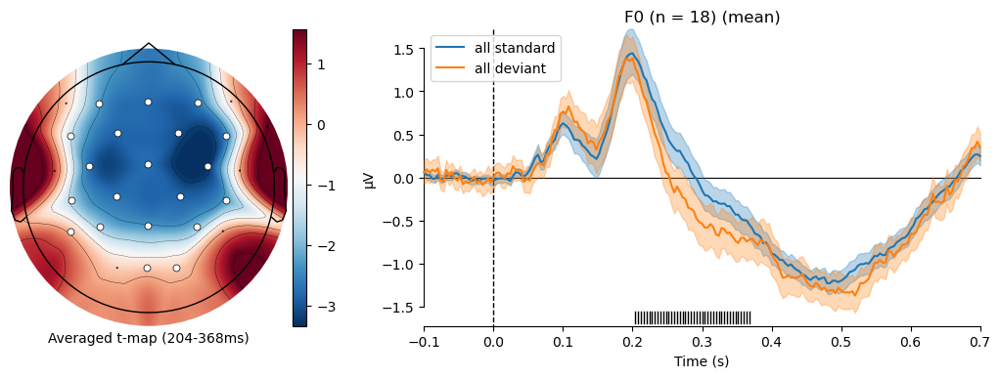

In [21]:
# read in participant file
df = pd.read_csv(work_dir + 'data_analysis/participants_include.txt', delimiter = '\t')
include_ppts = df[df['include']==1]['participant'].astype(str).tolist()

ref_channels = ['TP9', 'TP10']

# directory
input_dir = work_dir + 'data_preprocessed/5_evokeds/'
# get time and channel info from any evoked data
evoked = mne.read_evokeds(fname=input_dir+'F0_0001_ave.fif', condition='dorsal_highStan_lowDevi_stan')
evoked.drop_channels(ref_channels)
# channel adjacency
adjacency, chan_names = mne.channels.find_ch_adjacency(evoked.info, 'eeg')


all_inputs = os.listdir(input_dir)

# participants to exclude
exclude_ppts = [
]

for group in ['VOT', 'F0']:

    # get participant list
    subset_files = []
    for file in all_inputs:
        # if (ppt in ppt_dict[ppt_group]) and (ppt not in exclude_ppts) and (ppt not in subset_ppts):
        if file.endswith('.fif') and (file.split('_')[0] in group) and (file.rsplit('_',1)[0] in include_ppts) and (file.rsplit('_',1)[0] not in exclude_ppts):
            # append that subject to the list
            subset_files.append(file)

    # initialize erp data
    erp_diff = []

    # for each cell
    for cell in cell_dict[group].keys():

        # extract ERPs
        # for each participant
        for file in subset_files:
        
            # standard erp
            tmp_stan = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['stan'], verbose='WARNING')
            tmp_stan.drop_channels(ref_channels)
            
            # deviant erp
            tmp_devi = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['devi'], verbose='WARNING')
            tmp_devi.drop_channels(ref_channels)
            
            # compute temporary difference erp
            tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                          weights=[1,-1])
            # append temporary data to list
            erp_diff.append(tmp_diff)
        
            del tmp_stan, tmp_devi, tmp_diff

    # apply function
    good_clusters_idx, clusters, T_obs = myfunc_permutation(erp_diff)

    print('===== ' + group + ' significant clusters =====')
    print(good_clusters_idx)


    
    ## visualize clusters

    #######################
    #### visualization ####
    #######################
    
    #### parameter ####
    toggle_save_plot = False
    
    if len(good_clusters_idx) > 0:

        #### get plot data #####
        # get plot title
        permutation_wave_title = group + ' (n = ' + str(len(subset_files)) + ')'

        # apply function
        # get legends
        legend_stan = 'all standard'
        legend_devi = 'all deviant'
        # legend_diff = 'deviants minus standards'
        
        # extract ERPs for each condition
        erp_stan = []
        erp_devi = []

        # for each cell
        for cell in cell_dict[group].keys():
            # for each participant
            for file in subset_files:
            
                # standard erp
                tmp_stan = mne.read_evokeds(input_dir + file, 
                                            condition=cell_dict[group][cell]['stan'], verbose='WARNING')
                tmp_stan.drop_channels(ref_channels)
                
                # deviant erp
                tmp_devi = mne.read_evokeds(input_dir + file, 
                                            condition=cell_dict[group][cell]['devi'], verbose='WARNING')
                tmp_devi.drop_channels(ref_channels)
        
                # compute temporary difference erp
                tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                              weights=[1,-1])
                # append temporary data to list
                erp_stan.append(tmp_stan)
                erp_devi.append(tmp_devi)
        
        # organize data for plotting
        evokeds = {
            legend_stan: erp_stan,
            legend_devi: erp_devi,
        }


        #### plot ####
        # loop over clusters
        for ith_cluster in range(len(good_clusters_idx)):

            myfunc_permutation_plot()
    
            # save
            if toggle_save_plot:
                fig.savefig(output_dir + 'erp_permutation_' + group + '_' + mmn + '.png')

## Seoul Data

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/Seoul Data/eeg_preprocessed/5_evokeds/F0_0001_ave.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms (dorsal_highStan_lowDevi_stan)
        0 CTF compensation matrices available
        nave = 390 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
Loaded Evoked data is baseline-corrected (baseline: [-0.1, 0] s)
Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28
stat_fun(H1): min=-4.752405254374801 max=3.757724193947625
Running initial clustering …
Found 57 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== VOT iMMN_dorsal_longVOT significant clusters =====
[]
stat_fun(H1): min=-3.8177607467720893 max=3.9261775885976387
Running initial clustering …
Found 61 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== VOT iMMN_dorsal_shortVOT significant clusters =====
[]
stat_fun(H1): min=-4.503355338819548 max=4.7419723857689675
Running initial clustering …
Found 47 clusters


...

===== F0 iMMN_dorsal_lowF0 significant clusters =====
[]
stat_fun(H1): min=-6.652274222306864 max=6.764393545955636
Running initial clustering …
Found 62 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== F0 iMMN_glottal_highF0 significant clusters =====
[15 49]
['Oz' 'P8' 'TP8' 'P7' 'P3' 'O2' 'O1' 'TP7' 'T7']
combining channels using "mean"
combining channels using "mean"
['CPz' 'FC4' 'Cz' 'C3' 'FCz' 'Fz' 'F4' 'FC3' 'F3' 'C4']
combining channels using "mean"
combining channels using "mean"
stat_fun(H1): min=-4.288383211724345 max=5.400019739539554
Running initial clustering …
Found 66 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== F0 iMMN_glottal_lowF0 significant clusters =====
[30 65]
['Oz' 'P7' 'P3' 'O2' 'O1' 'TP7' 'T7' 'P4']
combining channels using "mean"
combining channels using "mean"
['FC4' 'CP4' 'Cz' 'FT8' 'FCz' 'Fz' 'F4' 'FC3' 'F3' 'C4']
combining channels using "mean"
combining channels using "mean"


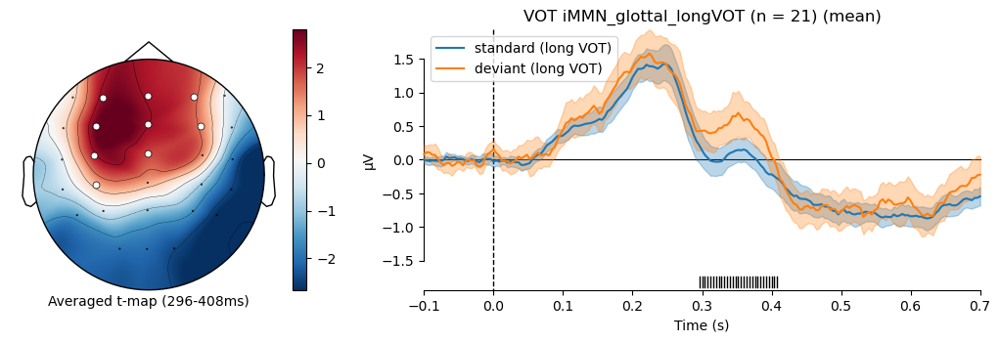

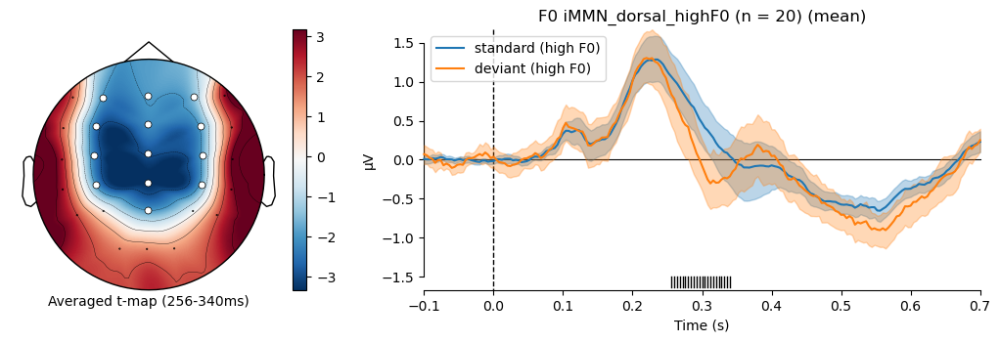

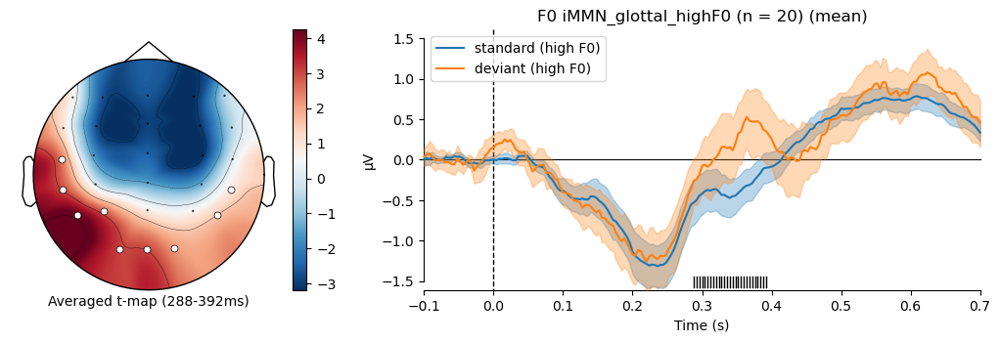

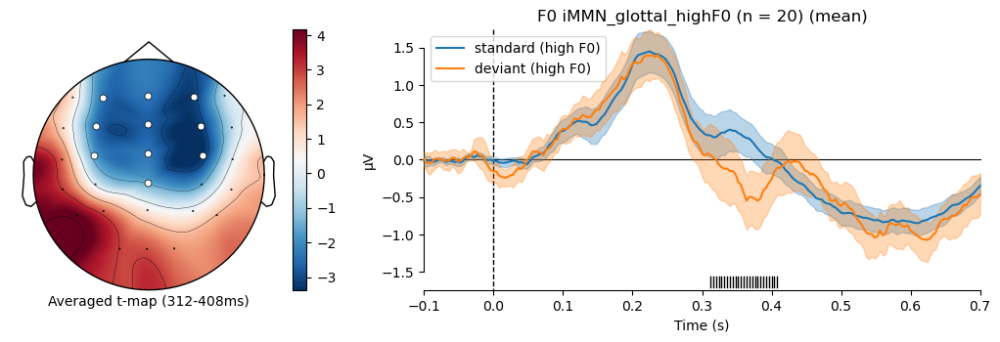

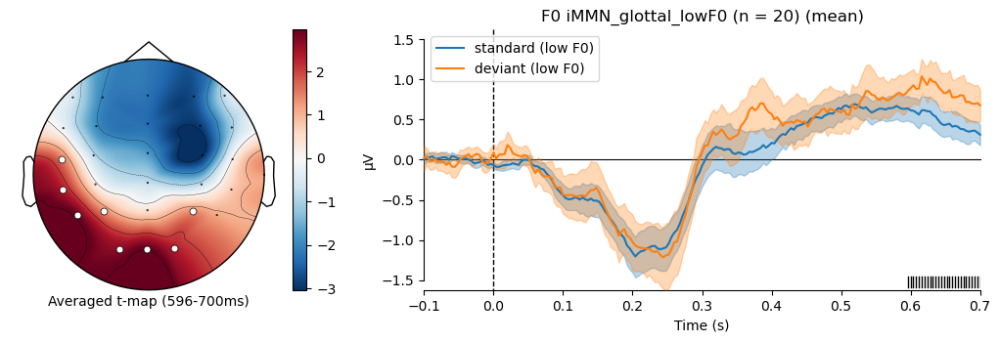

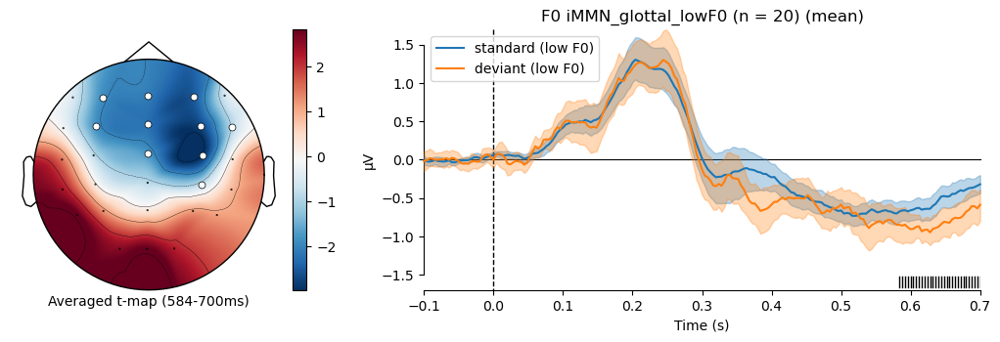

In [22]:
# directory
input_dir = work_dir + 'Seoul Data/eeg_preprocessed/5_evokeds/'

ref_channels = ['M1', 'M2']

# directory
# get time and channel info from any evoked data
evoked = mne.read_evokeds(fname=input_dir+'F0_0001_ave.fif', condition='dorsal_highStan_lowDevi_stan')
evoked.drop_channels(ref_channels)
# channel adjacency
adjacency, chan_names = mne.channels.find_ch_adjacency(evoked.info, 'eeg')

# all files
all_inputs = os.listdir(input_dir)

# participants to exclude
exclude_ppts = [
]

# for each group
for group in ['VOT', 'F0']:

    # get participant list
    subset_files = []
    for file in all_inputs:
        if file.endswith('.fif') and (file.split('_')[0] in group) and (file.rsplit('_',1)[0] not in exclude_ppts):
            # append that subject to the list
            subset_files.append(file)

    # for each cell
    for cell in cell_dict[group].keys():

        # initialize erp data
        erp_diff = []

        # extract ERPs
        # for each participant
        for file in subset_files:
        
            # standard erp
            tmp_stan = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['stan'], verbose='WARNING')
            tmp_stan.drop_channels(ref_channels)
            
            # deviant erp
            tmp_devi = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['devi'], verbose='WARNING')
            tmp_devi.drop_channels(ref_channels)
            
            # compute temporary difference erp
            tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                          weights=[1,-1])
            # append temporary data to list
            erp_diff.append(tmp_diff)
        
            del tmp_stan, tmp_devi, tmp_diff

        # apply function
        good_clusters_idx, clusters, T_obs = myfunc_permutation(erp_diff)

        print('===== ' + group + ' ' + cell + ' significant clusters =====')
        print(good_clusters_idx)
        
        ## visualize clusters

        #######################
        #### visualization ####
        #######################
        
        #### parameter ####
        toggle_save_plot = False
        
        if len(good_clusters_idx) > 0:

            # get plot title
            permutation_wave_title = group + ' ' + cell + ' (n = ' + str(len(subset_files)) + ')'

            # extract ERPs for each condition
            # for each cell

            # get legends
            legend_stan = 'standard (' + cell_dict[group][cell]['stan_stim'] + ')'
            legend_devi = 'deviant (' + cell_dict[group][cell]['devi_stim'] + ')'

            # initialize
            erp_stan = []
            erp_devi = []
            
            # for each participant
            for file in subset_files:
            
                # standard erp
                tmp_stan = mne.read_evokeds(input_dir + file, 
                                            condition=cell_dict[group][cell]['stan'], verbose='WARNING')
                tmp_stan.drop_channels(ref_channels)
                
                # deviant erp
                tmp_devi = mne.read_evokeds(input_dir + file, 
                                            condition=cell_dict[group][cell]['devi'], verbose='WARNING')
                tmp_devi.drop_channels(ref_channels)
        
                # compute temporary difference erp
                tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                              weights=[1,-1])
                # append temporary data to list
                erp_stan.append(tmp_stan)
                erp_devi.append(tmp_devi)
            
            # organize data for plotting
            evokeds = {
                legend_stan: erp_stan,
                legend_devi: erp_devi,
            }

                    
            # loop over clusters
            for ith_cluster in range(len(good_clusters_idx)):

                # apply plot function
                myfunc_permutation_plot()
        
                # save
                if toggle_save_plot:
                    fig.savefig(output_dir + 'erp_permutation_' + group + '_' + mmn + '.png')

### collapse all conditions

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/Seoul Data/eeg_preprocessed/5_evokeds/F0_0001_ave.fif ...
    Found the data of interest:
        t =    -100.00 ...     700.00 ms (dorsal_highStan_lowDevi_stan)
        0 CTF compensation matrices available
        nave = 390 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
Loaded Evoked data is baseline-corrected (baseline: [-0.1, 0] s)
Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28
stat_fun(H1): min=-3.6063872046694527 max=3.2523057176189334
Running initial clustering …
Found 34 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== VOT significant clusters =====
[]
stat_fun(H1): min=-5.186031709994661 max=5.738460285323111
Running initial clustering …
Found 27 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

===== F0 significant clusters =====
[20 24]
combining channels using "mean"
combining channels using "mean"
combining channels using "mean"
combining channels using "mean"


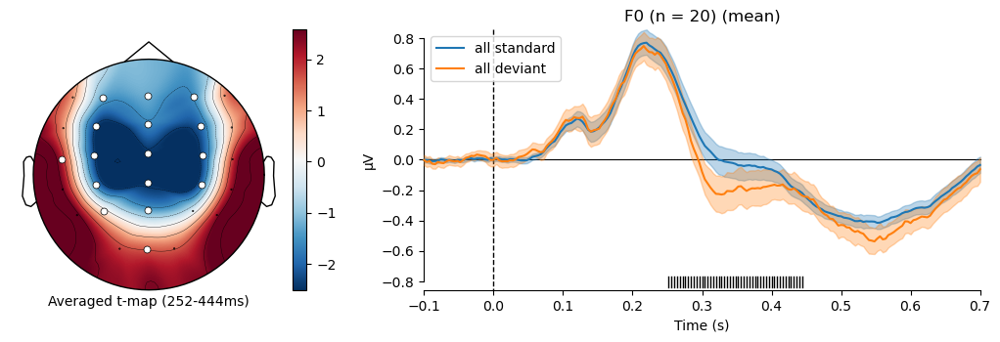

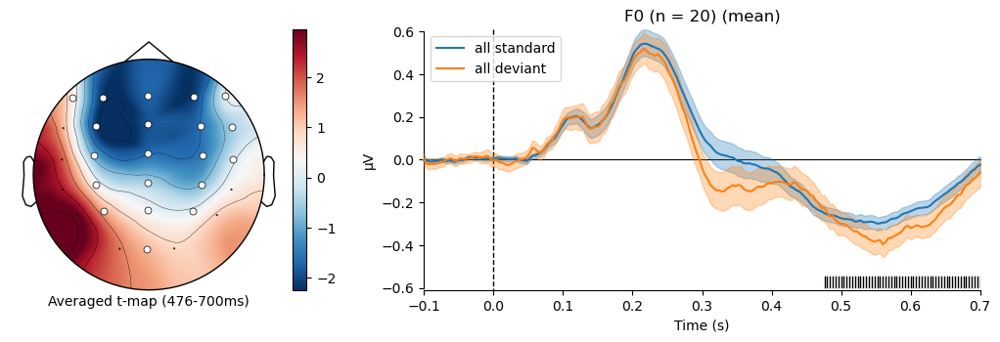

In [167]:
# directory
input_dir = work_dir + 'Seoul Data/eeg_preprocessed/5_evokeds/'

ref_channels = ['M1', 'M2']

# directory
# get time and channel info from any evoked data
evoked = mne.read_evokeds(fname=input_dir+'F0_0001_ave.fif', condition='dorsal_highStan_lowDevi_stan')
evoked.drop_channels(ref_channels)
# channel adjacency
adjacency, chan_names = mne.channels.find_ch_adjacency(evoked.info, 'eeg')

# all files
all_inputs = os.listdir(input_dir)

# participants to exclude
exclude_ppts = [
]

for group in ['VOT', 'F0']:

    # get participant list
    subset_files = []
    for file in all_inputs:
        # if (ppt in ppt_dict[ppt_group]) and (ppt not in exclude_ppts) and (ppt not in subset_ppts):
        if file.endswith('.fif') and (file.split('_')[0] in group) and (file.rsplit('_',1)[0] not in exclude_ppts):
            # append that subject to the list
            subset_files.append(file)

    # initialize erp data
    erp_diff = []

    # for each cell
    for cell in cell_dict[group].keys():

        # extract ERPs
        # for each participant
        for file in subset_files:
        
            # standard erp
            tmp_stan = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['stan'], verbose='WARNING')
            tmp_stan.drop_channels(ref_channels)
            
            # deviant erp
            tmp_devi = mne.read_evokeds(input_dir + file, 
                                        condition=cell_dict[group][cell]['devi'], verbose='WARNING')
            tmp_devi.drop_channels(ref_channels)
            
            # compute temporary difference erp
            tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                          weights=[1,-1])
            # append temporary data to list
            erp_diff.append(tmp_diff)
        
            del tmp_stan, tmp_devi, tmp_diff

    # apply function
    good_clusters_idx, clusters, T_obs = myfunc_permutation(erp_diff)

    print('===== ' + group + ' significant clusters =====')
    print(good_clusters_idx)


    
    ## visualize clusters

    #######################
    #### visualization ####
    #######################
    
    #### parameter ####
    toggle_save_plot = False
    
    if len(good_clusters_idx) > 0:

        #### get plot data #####
        # get plot title
        permutation_wave_title = group + ' (n = ' + str(len(subset_files)) + ')'

        # apply function
        # get legends
        legend_stan = 'all standard'
        legend_devi = 'all deviant'
        # legend_diff = 'deviants minus standards'
        
        # extract ERPs for each condition
        erp_stan = []
        erp_devi = []

        # for each cell
        for cell in cell_dict[group].keys():
            # for each participant
            for file in subset_files:
            
                # standard erp
                tmp_stan = mne.read_evokeds(input_dir + file, 
                                            condition=cell_dict[group][cell]['stan'], verbose='WARNING')
                tmp_stan.drop_channels(ref_channels)
                
                # deviant erp
                tmp_devi = mne.read_evokeds(input_dir + file, 
                                            condition=cell_dict[group][cell]['devi'], verbose='WARNING')
                tmp_devi.drop_channels(ref_channels)
        
                # compute temporary difference erp
                tmp_diff = mne.combine_evoked([tmp_devi, tmp_stan],
                                              weights=[1,-1])
                # append temporary data to list
                erp_stan.append(tmp_stan)
                erp_devi.append(tmp_devi)
        
        # organize data for plotting
        evokeds = {
            legend_stan: erp_stan,
            legend_devi: erp_devi,
        }


        #### plot ####
        # loop over clusters
        for ith_cluster in range(len(good_clusters_idx)):

            myfunc_permutation_plot()
    
            # save
            if toggle_save_plot:
                fig.savefig(output_dir + 'erp_permutation_' + group + '_' + mmn + '.png')

# Time-frequency plotting

In [35]:
# grand average
toggle_save_plot = False

# baseline
tfr_baseline = (-0.45, -0.3)

# condition list
condition_list = [
    'dorsal_highStan_lowDevi_stan',
    'dorsal_lowStan_highDevi_stan',
    'glottal_highStan_lowDevi_stan',
    'glottal_lowStan_highDevi_stan',
]

## Toronto data

Identifying common channels ...
No baseline correction applied


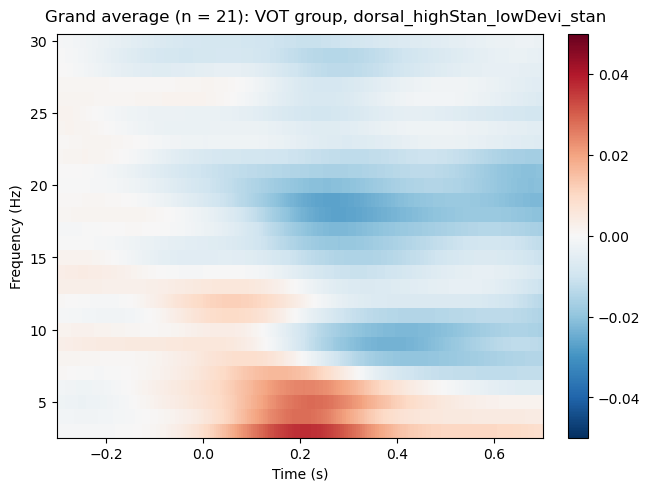

Identifying common channels ...
No baseline correction applied


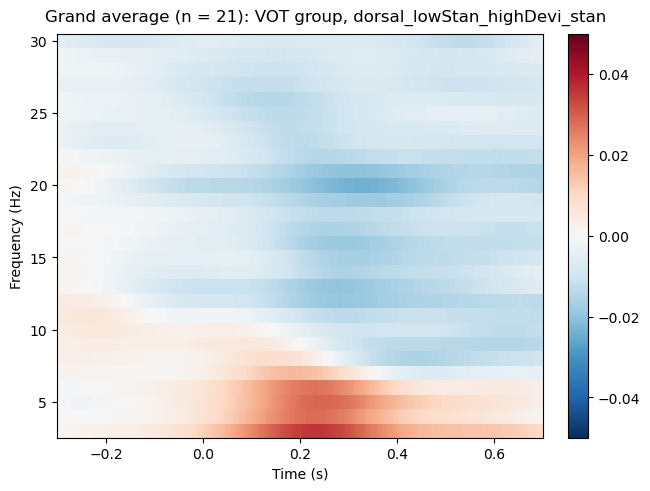

Identifying common channels ...
No baseline correction applied


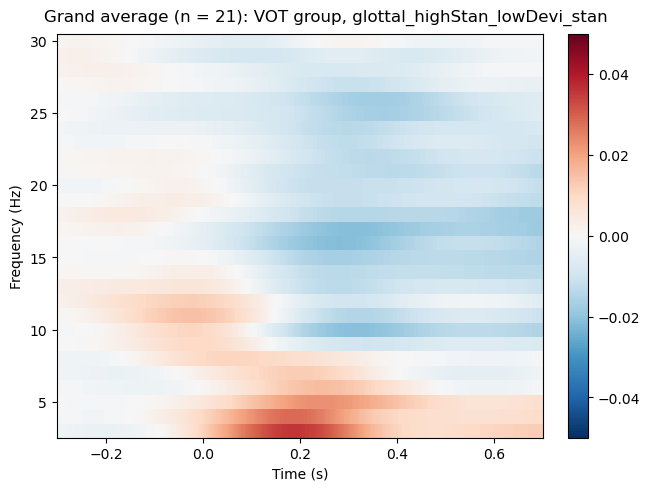

Identifying common channels ...
No baseline correction applied


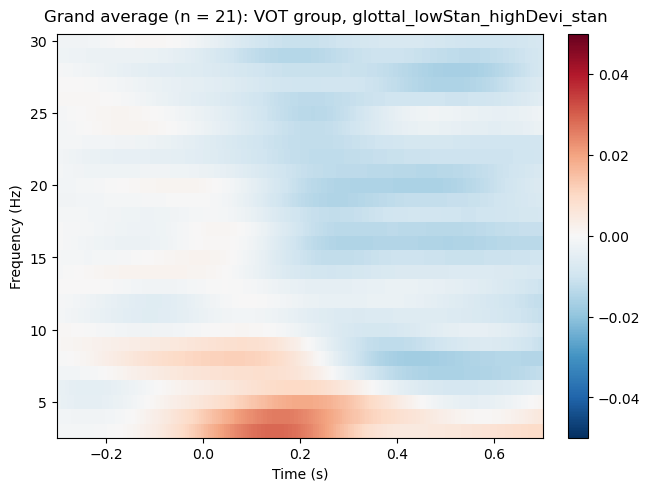

Identifying common channels ...
No baseline correction applied


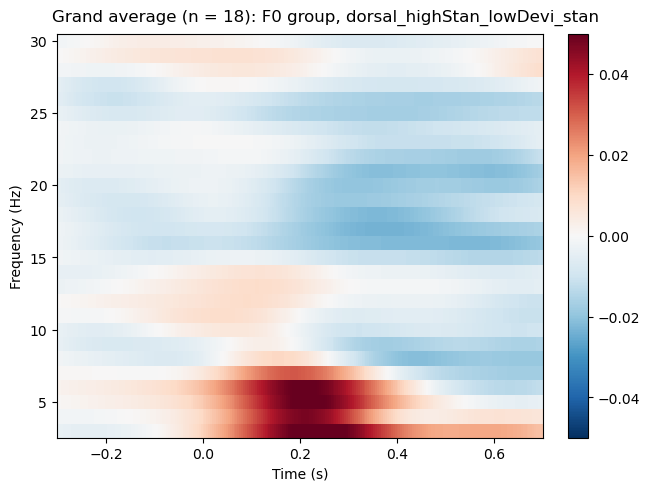

Identifying common channels ...
No baseline correction applied


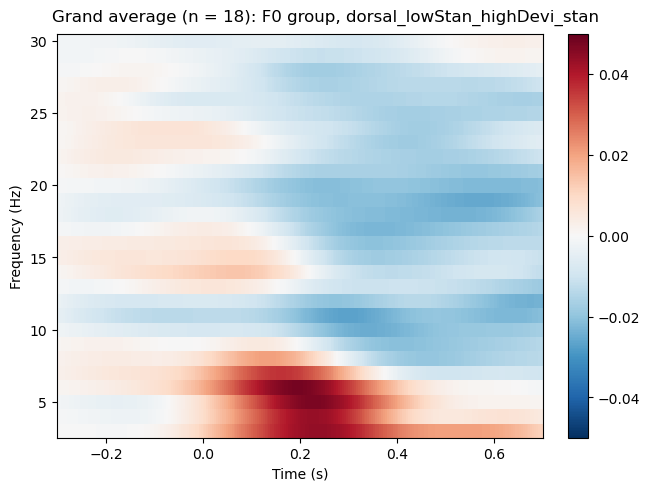

Identifying common channels ...
No baseline correction applied


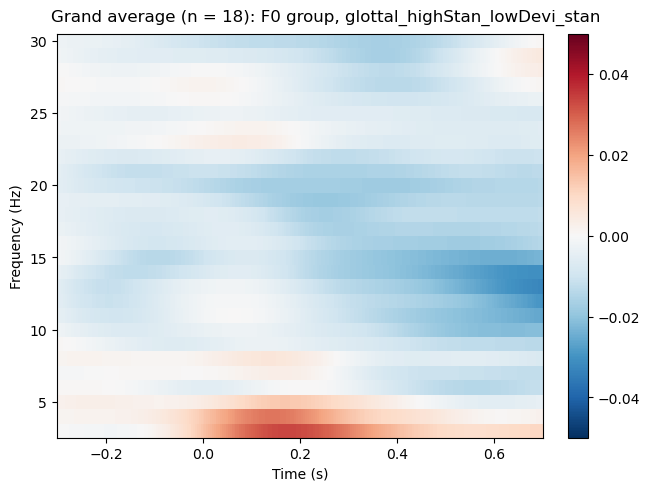

Identifying common channels ...
No baseline correction applied


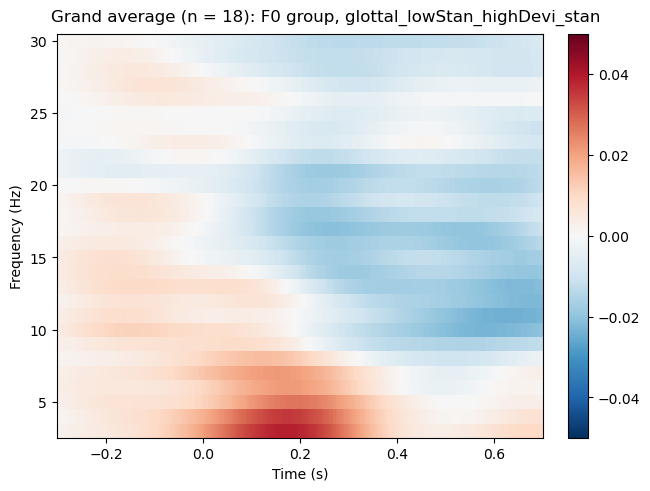

In [36]:
# directory
input_dir = work_dir + 'data_preprocessed/4_tfr_evokeds_unnormalized/'
output_dir = work_dir + 'figures/tfr/'

# read in participant file
df = pd.read_csv(work_dir + 'data_analysis/participants_include.txt', delimiter = '\t')
include_ppts = df[df['include']==1]['participant'].astype(str).tolist()

# exclude participants
exclude_ppts = [
]

# get file names
all_input = os.listdir(input_dir)

# for each group
for group in ['VOT', 'F0']:

    # for each condition
    for condition in condition_list:

        # initialize ERSP list
        tfrs = []
    
        for file in all_input:
    
            if file.endswith("tfr.hdf5") and (file.split('_')[0] in group) and (file.rsplit('_',1)[0] in include_ppts):
    
                # exclude bad data
                if file.rsplit('_',1)[0] in exclude_ppts:
                    continue
                
                # read in data
                power = mne.time_frequency.read_tfrs(fname=input_dir + file, condition=condition, verbose='WARNING')
    
                # drop reference channels
                power.drop_channels(['TP9', 'TP10'])
    
                # normalization
                power.apply_baseline(mode="logratio", baseline=tfr_baseline, verbose='WARNING')
    
                # append
                tfrs.append(power)
    
        # create a list of grand average differences
        tfrs = mne.grand_average(tfrs)
    
        # power
        fig = tfrs.plot(
            # picks='all', 
            combine = 'mean',
            tmin=-0.3, tmax=0.7,
            title= tfrs.comment + ': ' + group + ' group, ' + condition,
            vlim = (-0.05, 0.05)
        )
        
        # save fig
        if toggle_save_plot:
            fig[0].savefig(output_dir + 'power_' + group + '_' + condition +'.png')
    
        # release memory
        del tfrs

## Seoul data

Identifying common channels ...
No baseline correction applied


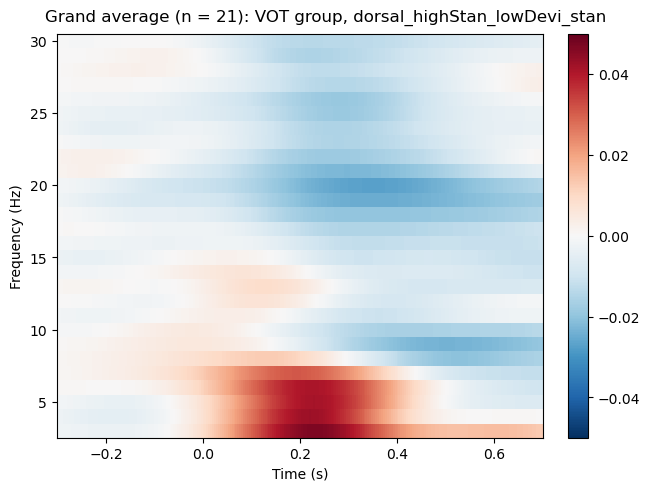

Identifying common channels ...
No baseline correction applied


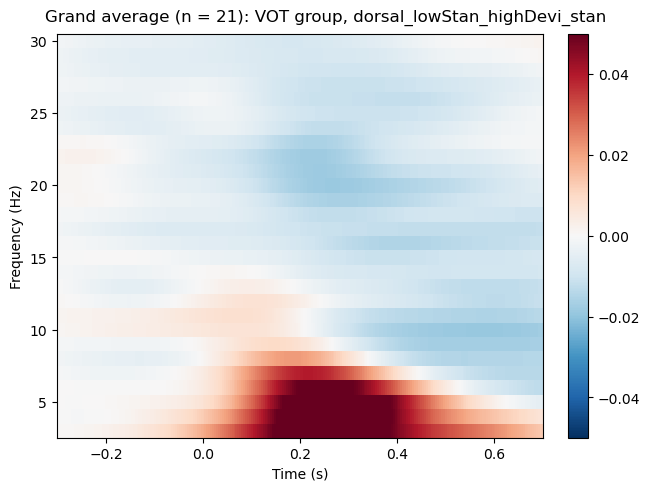

Identifying common channels ...
No baseline correction applied


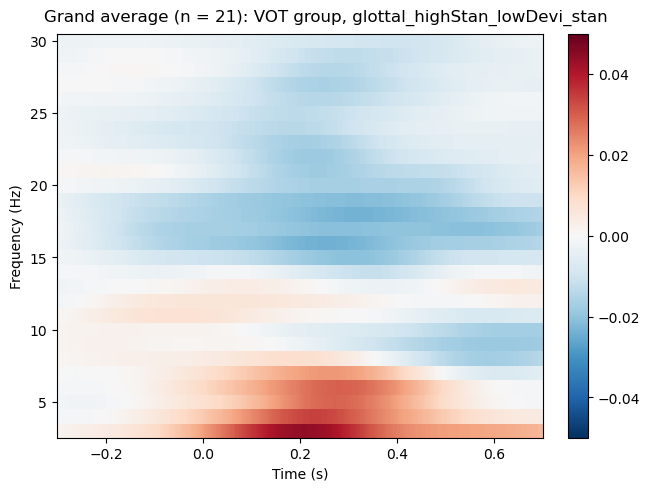

Identifying common channels ...
No baseline correction applied


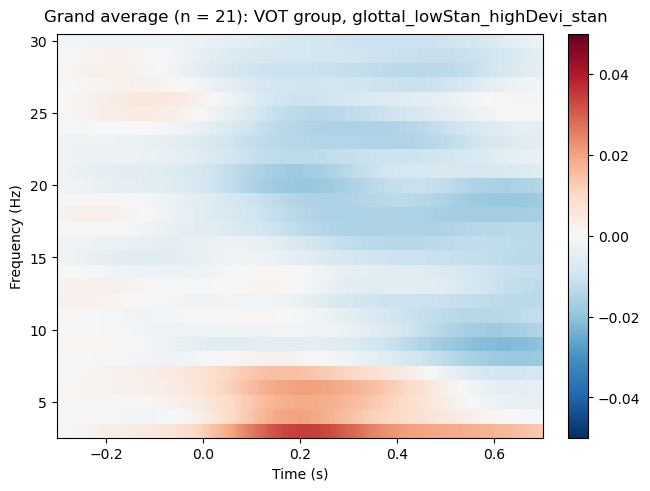

Identifying common channels ...
No baseline correction applied


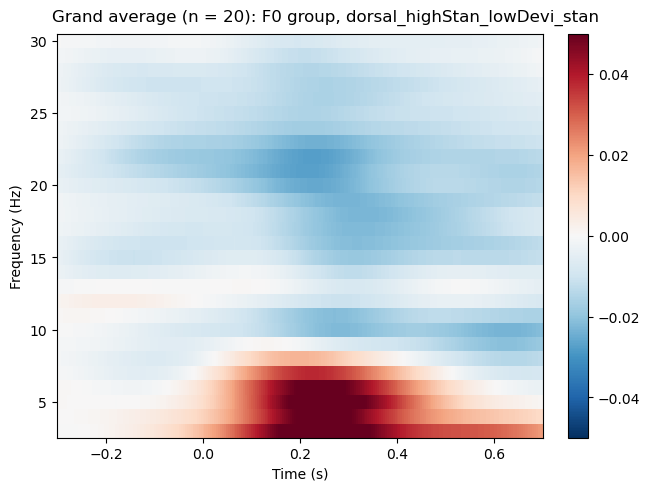

Identifying common channels ...
No baseline correction applied


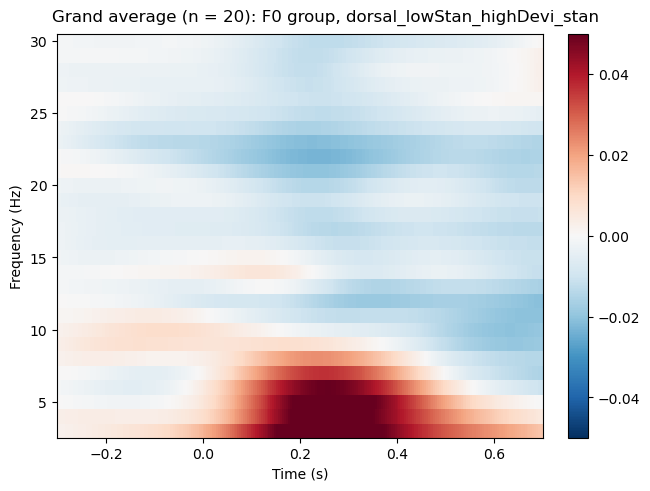

Identifying common channels ...
No baseline correction applied


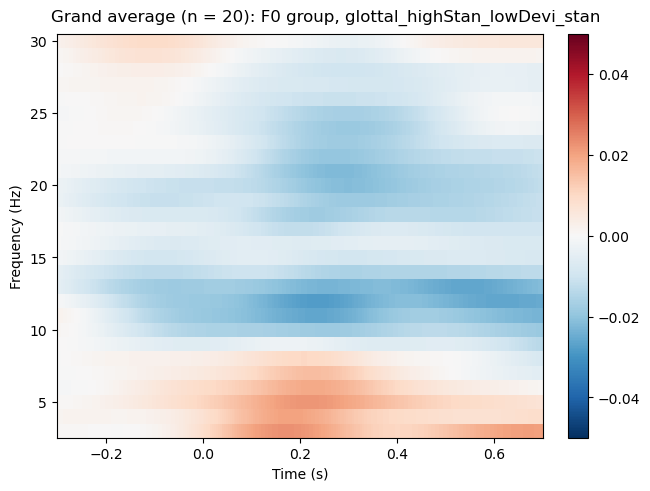

Identifying common channels ...
No baseline correction applied


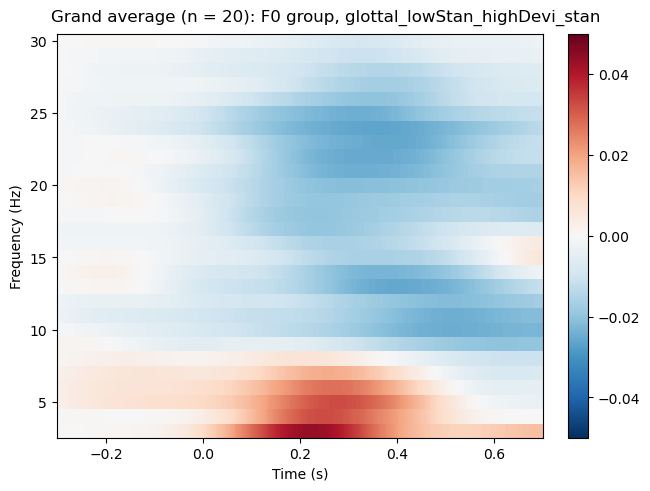

In [37]:
# directory
input_dir = work_dir + 'Seoul Data/eeg_preprocessed/4_tfr_evokeds_unnormalized/'
output_dir = work_dir + 'Seoul Data/figures/tfr/'

# exclude participants
exclude_ppts = [
]

# get file names
all_input = os.listdir(input_dir)

# for each group
for group in ['VOT', 'F0']:

    # for each condition
    for condition in condition_list:

        # initialize ERSP list
        tfrs = []
    
        for file in all_input:
    
            if file.endswith("tfr.hdf5") and (file.split('_')[0] in group):
    
                # exclude bad data
                if file.rsplit('_',1)[0] in exclude_ppts:
                    continue
                
                # read in data
                power = mne.time_frequency.read_tfrs(fname=input_dir + file, condition=condition, verbose='WARNING')
    
                # drop reference channels
                power.drop_channels(['M1', 'M2'])
    
                # normalization
                power.apply_baseline(mode="logratio", baseline=tfr_baseline, verbose='WARNING')
    
                # append
                tfrs.append(power)
    
        # create a list of grand average differences
        tfrs = mne.grand_average(tfrs)
    
        # power
        fig = tfrs.plot(
            # picks='all', 
            combine = 'mean',
            tmin=-0.3, tmax=0.7,
            title= tfrs.comment + ': ' + group + ' group, ' + condition,
            vlim = (-0.05, 0.05)
        )
        
        # save fig
        if toggle_save_plot:
            fig[0].savefig(output_dir + 'power_' + group + '_' + condition +'.png')
    
        # release memory
        del tfrs

# Time frequency permutation

## Toronto data

In [156]:
# directory
input_dir = work_dir + 'data_preprocessed/4_tfr_evokeds_unnormalized/'
output_dir = work_dir + 'data_analysis/'

# read in participant file
df = pd.read_csv(work_dir + 'data_analysis/participants_include.txt', delimiter = '\t')
include_ppts = df[df['include']==1]['participant'].astype(str).tolist()

# reference channels
ref_channels = ['TP9', 'TP10']

# exclude bad participants
exclude_ppts = [
]

tfr_evoked = mne.time_frequency.read_tfrs(fname=input_dir + 'F0_0001_tfr.hdf5')[0]
tfr_evoked.drop_channels(ref_channels)
tfr_evoked = tfr_evoked.crop(-0.3, 0.7)
# find_ch_adjacency first attempts to find an existing "neighbor"
# (adjacency) file for given sensor layout.
# If such a file doesn't exist, an adjacency matrix is computed on the fly,
# using Delaunay triangulations.
sensor_adjacency, ch_names = mne.channels.find_ch_adjacency(tfr_evoked.info, ch_type='eeg')

# # visualize
# mne.viz.plot_ch_adjacency(tfr_evoked.info, sensor_adjacency, ch_names)
# plt.show()
                                                            
adjacency = mne.stats.combine_adjacency(
    sensor_adjacency, len(tfr_evoked.freqs), len(tfr_evoked.times)
)
# The overall adjacency we end up with is a square matrix with each
# dimension matching the data size (excluding observations) in an
# "unrolled" format, so: len(channels × frequencies × times)


# baseline
tfr_baseline = (-0.45, -0.3)


# get file names
all_input = os.listdir(input_dir)


diff_dict = {
    'dorsal highStan minus lowStan': ['dorsal_highStan_lowDevi_stan', 'dorsal_lowStan_highDevi_stan'],
    'glottal highStan minus lowStan': ['glottal_highStan_lowDevi_stan', 'glottal_lowStan_highDevi_stan'],
}

# for each group
for group in ['VOT', 'F0']:

    # for each difference cell
    for diff_key in diff_dict.keys():

        # get conditions
        cond1 = diff_dict[diff_key][0]
        cond2 = diff_dict[diff_key][1]
        
        # initialize ERSP list
        tfrs = []
        
        for file in all_input:
        
            if file.endswith("_tfr.hdf5") and (file.split('_')[0] in group) and and (file.rsplit('_',1)[0] in include_ppts):
        
                # exclude bad data
                if file.rsplit('_',1)[0] in exclude_ppts:
                    continue
                
                # read in data
                power1 = mne.time_frequency.read_tfrs(fname=input_dir + file, condition=cond1, verbose='WARNING')
                power1.drop_channels(ref_channels)
                power2 = mne.time_frequency.read_tfrs(fname=input_dir + file, condition=cond2, verbose='WARNING')
                power2.drop_channels(ref_channels)
                # Baseline power
                power1.apply_baseline(mode="logratio", baseline=tfr_baseline, verbose='WARNING')       
                power2.apply_baseline(mode="logratio", baseline=tfr_baseline, verbose='WARNING')        
                power_diff = power1 - power2
        
                # crop
                power_diff.crop(-0.3, 0.7)
        
                # append
                tfrs.append(power_diff)
        
                # release memory
                del power1, power2, power_diff
        
        
        # extract data for stats
        X = [x.data for x in tfrs]
        X = np.stack(X, axis=0)
        # X.shape # observation x channel x frequency x time
        
        
        # In this example, we wish to set the threshold for including data bins in
        # the cluster forming process to the t-value corresponding to p=0.001 for the
        # given data.
        #
        # Because we conduct a two-tailed test, we divide the p-value by 2 (which means
        # we're making use of both tails of the distribution).
        # As the degrees of freedom, we specify the number of observations
        # (here: epochs) minus 1.
        # Finally, we subtract 0.001 / 2 from 1, to get the critical t-value
        # on the right tail (this is needed for MNE-Python internals)
        tail = 0
        p_thresh = 0.05
        degrees_of_freedom = X.shape[0] - 1
        t_thresh = scipy.stats.t.ppf(1 - p_thresh / 2, df=degrees_of_freedom)
        
        
        # Run the analysis
        T_obs, clusters, cluster_p_values, H0 = mne.stats.permutation_cluster_1samp_test(
            X,
            threshold=t_thresh,
            tail=tail,
            adjacency=adjacency,
            out_type="mask",
            # seed = 42,
            verbose=True,
        )
        
        #########################
        #### select clusters ####
        #########################
        
        # Select the clusters that are statistically significant at p < 0.05
        p_accept = 0.05
        good_clusters_idx = np.where(cluster_p_values < p_accept)[0]
        
        print('==== ' + group + ' group: ' + diff_key + ', Significant Clusters ====')
        print(good_clusters_idx)
        
        # plot
        if len(good_clusters_idx)>0:
            times = tfr_evoked.times
            freqs = tfr_evoked.freqs
            fig, ax = plt.subplots(1, layout="constrained")
            
            T_obs_plot = np.nan * np.ones_like(T_obs)
            for c, p_val in zip(clusters, cluster_p_values):
                if p_val <= p_accept:
                    T_obs_plot[c] = T_obs[c]
            
            # Just plot one channel's data
            # use the following to show a specific one:
            # ch_idx = tfr_epochs.ch_names.index('MEG 1332')
            ch_idx, f_idx, t_idx = np.unravel_index(
                np.nanargmax(np.abs(T_obs_plot)), X.shape[1:]
            )
            
            vmax = np.max(np.abs(T_obs))
            vmin = -vmax
            # ax.imshow(
            #     T_obs[ch_idx],
            #     cmap=plt.cm.grey,
            #     extent=[times[0], times[-1], freqs[0], freqs[-1]],
            #     aspect="auto",
            #     origin="lower",
            #     vmin=vmin,
            #     vmax=vmax,
            # )
            ax.imshow(
                T_obs_plot[ch_idx],
                cmap=plt.cm.RdBu_r,
                extent=[times[0], times[-1], freqs[0], freqs[-1]],
                aspect="auto",
                origin="lower",
                vmin=vmin,
                vmax=vmax,
            )
            fig.colorbar(ax.images[0])
            
            ax.set_title(group + ' group: ' + diff_key)
            ax.set(xlabel="Time (s)", ylabel="Frequency (Hz)")
            # ax.set(title=f"Induced power ({tfr_epochs.ch_names[ch_idx]})")
            
            # evoked.plot(axes=[ax2], time_unit="s")

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/data_preprocessed/4_tfr_evokeds_unnormalized/F0_0001_tfr.hdf5 ...
Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28
stat_fun(H1): min=-3.9720360752475306 max=4.123542036894202
Running initial clustering …
Found 84 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

==== VOT group: dorsal highStan minus lowStan, Significant Clusters ====
[]
stat_fun(H1): min=-3.722163121103403 max=5.495567728478692
Running initial clustering …
Found 61 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

==== VOT group: glottal highStan minus lowStan, Significant Clusters ====
[]
stat_fun(H1): min=-4.108074588330479 max=3.621526756907426
Running initial clustering …
Found 53 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

==== F0 group: dorsal highStan minus lowStan, Significant Clusters ====
[]
stat_fun(H1): min=-4.561886996199438 max=3.292792471310232
Running initial clustering …
Found 42 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

==== F0 group: glottal highStan minus lowStan, Significant Clusters ====
[]


## Seoul data

In [157]:
# directory
input_dir = work_dir + 'Seoul Data/eeg_preprocessed/4_tfr_evokeds_unnormalized/'
output_dir = work_dir + 'Seoul Data/figures/tfr/'

ref_channels = ['M1', 'M2']

# exclude bad participants
exclude_ppts = [
]

tfr_evoked = mne.time_frequency.read_tfrs(fname=input_dir + 'F0_0001_tfr.hdf5')[0]
tfr_evoked.drop_channels(ref_channels)
tfr_evoked = tfr_evoked.crop(-0.3, 0.7)
# find_ch_adjacency first attempts to find an existing "neighbor"
# (adjacency) file for given sensor layout.
# If such a file doesn't exist, an adjacency matrix is computed on the fly,
# using Delaunay triangulations.
sensor_adjacency, ch_names = mne.channels.find_ch_adjacency(tfr_evoked.info, ch_type='eeg')

# # visualize
# mne.viz.plot_ch_adjacency(tfr_evoked.info, sensor_adjacency, ch_names)
# plt.show()
                                                            
adjacency = mne.stats.combine_adjacency(
    sensor_adjacency, len(tfr_evoked.freqs), len(tfr_evoked.times)
)
# The overall adjacency we end up with is a square matrix with each
# dimension matching the data size (excluding observations) in an
# "unrolled" format, so: len(channels × frequencies × times)


# baseline
tfr_baseline = (-0.45, -0.3)


# get file names
all_input = os.listdir(input_dir)


diff_dict = {
    'dorsal highStan minus lowStan': ['dorsal_highStan_lowDevi_stan', 'dorsal_lowStan_highDevi_stan'],
    'glottal highStan minus lowStan': ['glottal_highStan_lowDevi_stan', 'glottal_lowStan_highDevi_stan'],
}

# for each group
for group in ['VOT', 'F0']:

    # for each difference cell
    for diff_key in diff_dict.keys():

        # get conditions
        cond1 = diff_dict[diff_key][0]
        cond2 = diff_dict[diff_key][1]
        
        # initialize ERSP list
        tfrs = []
        
        for file in all_input:
        
            if file.endswith("_tfr.hdf5") and (file.split('_')[0] in group):
        
                # exclude bad data
                if file.rsplit('_',1)[0] in exclude_ppts:
                    continue
                
                # read in data
                power1 = mne.time_frequency.read_tfrs(fname=input_dir + file, condition=cond1, verbose='WARNING')
                power1.drop_channels(ref_channels)
                power2 = mne.time_frequency.read_tfrs(fname=input_dir + file, condition=cond2, verbose='WARNING')
                power2.drop_channels(ref_channels)
                # Baseline power
                power1.apply_baseline(mode="logratio", baseline=tfr_baseline, verbose='WARNING')       
                power2.apply_baseline(mode="logratio", baseline=tfr_baseline, verbose='WARNING')        
                power_diff = power1 - power2
        
                # crop
                power_diff.crop(-0.3, 0.7)
        
                # append
                tfrs.append(power_diff)
        
                # release memory
                del power1, power2, power_diff
        
        
        # extract data for stats
        X = [x.data for x in tfrs]
        X = np.stack(X, axis=0)
        # X.shape # observation x channel x frequency x time
        
        
        # In this example, we wish to set the threshold for including data bins in
        # the cluster forming process to the t-value corresponding to p=0.001 for the
        # given data.
        #
        # Because we conduct a two-tailed test, we divide the p-value by 2 (which means
        # we're making use of both tails of the distribution).
        # As the degrees of freedom, we specify the number of observations
        # (here: epochs) minus 1.
        # Finally, we subtract 0.001 / 2 from 1, to get the critical t-value
        # on the right tail (this is needed for MNE-Python internals)
        tail = 0
        p_thresh = 0.05
        degrees_of_freedom = X.shape[0] - 1
        t_thresh = scipy.stats.t.ppf(1 - p_thresh / 2, df=degrees_of_freedom)
        
        
        # Run the analysis
        T_obs, clusters, cluster_p_values, H0 = mne.stats.permutation_cluster_1samp_test(
            X,
            threshold=t_thresh,
            tail=tail,
            adjacency=adjacency,
            out_type="mask",
            # seed = 42,
            verbose=True,
        )
        
        #########################
        #### select clusters ####
        #########################
        
        # Select the clusters that are statistically significant at p < 0.05
        p_accept = 0.05
        good_clusters_idx = np.where(cluster_p_values < p_accept)[0]
        
        print('==== ' + group + ' group: ' + diff_key + ', Significant Clusters ====')
        print(good_clusters_idx)
        
        # plot
        if len(good_clusters_idx)>0:
            times = tfr_evoked.times
            freqs = tfr_evoked.freqs
            fig, ax = plt.subplots(1, layout="constrained")
            
            T_obs_plot = np.nan * np.ones_like(T_obs)
            for c, p_val in zip(clusters, cluster_p_values):
                if p_val <= p_accept:
                    T_obs_plot[c] = T_obs[c]
            
            # Just plot one channel's data
            # use the following to show a specific one:
            # ch_idx = tfr_epochs.ch_names.index('MEG 1332')
            ch_idx, f_idx, t_idx = np.unravel_index(
                np.nanargmax(np.abs(T_obs_plot)), X.shape[1:]
            )
            
            vmax = np.max(np.abs(T_obs))
            vmin = -vmax
            # ax.imshow(
            #     T_obs[ch_idx],
            #     cmap=plt.cm.grey,
            #     extent=[times[0], times[-1], freqs[0], freqs[-1]],
            #     aspect="auto",
            #     origin="lower",
            #     vmin=vmin,
            #     vmax=vmax,
            # )
            ax.imshow(
                T_obs_plot[ch_idx],
                cmap=plt.cm.RdBu_r,
                extent=[times[0], times[-1], freqs[0], freqs[-1]],
                aspect="auto",
                origin="lower",
                vmin=vmin,
                vmax=vmax,
            )
            fig.colorbar(ax.images[0])
            
            ax.set_title(group + ' group: ' + diff_key)
            ax.set(xlabel="Time (s)", ylabel="Frequency (Hz)")
            # ax.set(title=f"Induced power ({tfr_epochs.ch_names[ch_idx]})")
            
            # evoked.plot(axes=[ax2], time_unit="s")

Reading /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/Seoul Data/eeg_preprocessed/4_tfr_evokeds_unnormalized/F0_0001_tfr.hdf5 ...
Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28
stat_fun(H1): min=-3.9499730996394766 max=3.8112274894421323
Running initial clustering …
Found 72 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

==== VOT group: dorsal highStan minus lowStan, Significant Clusters ====
[]
stat_fun(H1): min=-5.982361661189017 max=4.659946566758793
Running initial clustering …
Found 62 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

==== VOT group: glottal highStan minus lowStan, Significant Clusters ====
[]
stat_fun(H1): min=-4.4870664834079035 max=3.2673593871813127
Running initial clustering …
Found 62 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

==== F0 group: dorsal highStan minus lowStan, Significant Clusters ====
[]
stat_fun(H1): min=-3.9855806910477343 max=5.6942644967247125
Running initial clustering …
Found 76 clusters


  0%|          | Permuting : 0/1023 [00:00<?,       ?it/s]

==== F0 group: glottal highStan minus lowStan, Significant Clusters ====
[]
